# 05 — Elo Optimization — Final Search

In the previous notebooks I found that Elo improves the chronological UFC fight prediction model, and the first optimization pass identified a promising parameter region.

This notebook performs the **final development-stage Elo search** before opening the untouched test set.

The main decisions already supported by the previous experiments are:

- the final model should use **Raw Elo**, not inactivity-adjusted Effective Elo;
- inactivity should remain available as an independent model feature;
- Elo decay should be disabled unless a new experiment clearly justifies it;
- the final configuration should not be selected from a single validation window only.

The goals of this final notebook are:

1. Run the expanded General Elo search.
2. Run a broader Striking Elo search.
3. Run a broader Grappling Offense / Grappling Defense search.
4. Recheck the Elo confidence prior.
5. Keep Elo decay disabled and remove Effective Elo from the final model feature set.
6. Run a joint search around the best parameter regions.
7. Select the final Elo configuration using **temporal robustness**, not only the primary validation window.
8. Bootstrap the final candidate against the baseline.
9. Save a production-ready `best_elo_config.json`.
10. Keep the final 15% test period untouched until I explicitly decide to open it.

The final test remains disabled by default.

## Final-search methodology

I do **not** optimize CatBoost hyperparameters in this notebook.

The CatBoost configuration stays fixed so that changes in performance can be attributed mainly to the Elo system.

The search follows this order:

1. General Elo.
2. Striking Elo.
3. Grappling Elo.
4. Confidence.
5. Joint confirmation.
6. Temporal robustness.
7. Paired bootstrap.

I use chronological data only.

The primary optimization metric is **Log Loss**, because this project is intended to produce useful fight probabilities rather than only hard winner classifications.

### Important final design decision

Effective Elo is retained internally only where I need to reproduce or compare the old Elo implementation during the General Elo experiment.

It is **not used as a final model feature**.

The production candidate uses:

- Raw General Elo
- Raw Striking Elo
- Raw Grappling Offense Elo
- Raw Grappling Defense Elo
- Elo confidence features
- debutant indicators
- inactivity in days

The Elo rating itself is not shrunk because of inactivity. I let the machine-learning model learn the relationship between inactivity and fight outcomes from the inactivity features.

In [49]:
from __future__ import annotations

from dataclasses import dataclass
from itertools import product
import json
import math
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)


## Project paths and search budget

`FAST_MODE=True` keeps the search practical while I am developing the Elo system.

Once the notebook is stable, I can switch it to `False` to test a larger sample of Striking and Grappling configurations.

The final test is deliberately disabled.

In [50]:
def find_project_root() -> Path:
    # I search upwards so this notebook works from either /notebooks or the project root.
    starts = [Path.cwd(), Path.cwd().parent]

    for start in starts:
        for path in [start, *start.parents]:
            if (path / "src").exists() and (path / "data").exists():
                return path

    raise FileNotFoundError(
        "Could not locate the UFC_PREDICTOR project root."
    )


PROJECT_ROOT = find_project_root()

INTERIM_DIR = PROJECT_ROOT / "data" / "interim" / "ufcstats"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ufcstats"
RESULTS_DIR = PROJECT_ROOT / "reports" / "elo_optimization_final"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FIGHTS_PATH = INTERIM_DIR / "fights_clean.parquet"
DETAILS_PATH = INTERIM_DIR / "fight_details_clean.parquet"
TOTALS_PATH = INTERIM_DIR / "fight_totals_clean.parquet"

DATASET_PATH = PROCESSED_DIR / "fight_dataset.parquet"
DATASET_REPORT_PATH = PROCESSED_DIR / "fight_dataset_report.json"

# This is the final development search, so I use the larger search budget.
FAST_MODE = False

# I still keep the untouched test set closed.
RUN_FINAL_TEST = False

# Search-model settings. I keep these fixed for every Elo candidate.
SEARCH_MODEL_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": 800,
    "learning_rate": 0.03,
    "depth": 6,
    "l2_leaf_reg": 5.0,
    "random_seed": RANDOM_SEED,
    "verbose": False,
    "allow_writing_files": False,
}

FINAL_MODEL_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": 1200,
    "learning_rate": 0.03,
    "depth": 6,
    "l2_leaf_reg": 5.0,
    "random_seed": RANDOM_SEED,
    "verbose": False,
    "allow_writing_files": False,
}

# Expanded deterministic search budgets.
N_STRIKING_CANDIDATES = 30
N_GRAPPLING_CANDIDATES = 40
N_JOINT_CANDIDATES = 12
N_ROBUSTNESS_CANDIDATES = 5
N_BOOTSTRAP = 3000

print("Project root:", PROJECT_ROOT)
print("Final expanded search:", not FAST_MODE)
print("Final test enabled:", RUN_FINAL_TEST)
print("Results directory:", RESULTS_DIR)

Project root: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR
Final expanded search: True
Final test enabled: False
Results directory: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\elo_optimization_final


## Load the historical data and the current fight dataset

I need both levels of data:

- the clean historical UFCStats tables, because every Elo candidate must be replayed chronologically;
- the current fight-level dataset, because I keep the original baseline features unchanged and replace only the Elo block.

In [51]:
required_paths = [
    FIGHTS_PATH,
    DETAILS_PATH,
    TOTALS_PATH,
    DATASET_PATH,
    DATASET_REPORT_PATH,
]

missing = [path for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Required files are missing:\n" +
        "\n".join(f"  - {path}" for path in missing)
    )

fights = pd.read_parquet(FIGHTS_PATH)
details = pd.read_parquet(DETAILS_PATH)
totals = pd.read_parquet(TOTALS_PATH)
df = pd.read_parquet(DATASET_PATH)

with DATASET_REPORT_PATH.open("r", encoding="utf-8") as f:
    dataset_report = json.load(f)

fights["event_date"] = pd.to_datetime(fights["event_date"])
df["event_date"] = pd.to_datetime(df["event_date"])

print(f"Clean fights: {len(fights):,}")
print(f"Fight totals rows: {len(totals):,}")
print(f"Training dataset rows: {len(df):,}")
print(f"Training dataset columns: {len(df.columns):,}")
print(f"Training date range: {df['event_date'].min().date()} -> {df['event_date'].max().date()}")


Clean fights: 8,949
Fight totals rows: 17,732
Training dataset rows: 8,731
Training dataset columns: 170
Training date range: 1994-03-11 -> 2026-09-12


## Recreate the same chronological split

I keep the exact 70 / 15 / 15 chronological structure used in the previous notebook.

The final 15% is not used during optimization.

In [52]:
df = (
    df.sort_values(
        ["event_date", "event_id", "fight_order"],
        ascending=[True, True, False],
        kind="stable",
    )
    .reset_index(drop=True)
)

n = len(df)
train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train_idx = np.arange(0, train_end)
validation_idx = np.arange(train_end, validation_end)
test_idx = np.arange(validation_end, n)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(train_idx), len(validation_idx), len(test_idx)],
    "date_min": [
        df.iloc[train_idx]["event_date"].min(),
        df.iloc[validation_idx]["event_date"].min(),
        df.iloc[test_idx]["event_date"].min(),
    ],
    "date_max": [
        df.iloc[train_idx]["event_date"].max(),
        df.iloc[validation_idx]["event_date"].max(),
        df.iloc[test_idx]["event_date"].max(),
    ],
    "target_rate": [
        df.iloc[train_idx]["target"].mean(),
        df.iloc[validation_idx]["target"].mean(),
        df.iloc[test_idx]["target"].mean(),
    ],
})

display(split_summary)


,split,rows,date_min,date_max,target_rate
0,train,6111,1994-03-11,2021-08-07,0.507937
1,validation,1310,2021-08-07,2024-03-16,0.489313
2,test,1310,2024-03-16,2026-09-12,0.476336


## Separate the original baseline features from Elo

The existing dataset already contains the current Elo implementation.

For this notebook I remove all current Elo columns from the model feature set and dynamically inject the candidate Elo features generated by each experiment.

This prevents the current configuration from leaking into another candidate.

In [53]:
manifest = dataset_report["feature_manifest"]

manifest_numeric = [
    col for col in manifest["numeric_model_features"]
    if col in df.columns
]
manifest_categorical = [
    col for col in manifest["categorical_model_features"]
    if col in df.columns
]

all_manifest_features = list(dict.fromkeys(
    manifest_numeric + manifest_categorical
))

def is_existing_elo_feature(column: str) -> bool:
    return (
        "elo_" in column
        or column.endswith("_is_debutant")
    )

baseline_features = [
    col for col in all_manifest_features
    if not is_existing_elo_feature(col)
]

categorical_features = [
    col for col in manifest_categorical
    if col in baseline_features
]

print("Original model features:", len(all_manifest_features))
print("Baseline features without Elo:", len(baseline_features))
print("Categorical baseline features:", len(categorical_features))


Original model features: 160
Baseline features without Elo: 116
Categorical baseline features: 5


# Parameterized Elo simulator

The following implementation mirrors the production Elo builder, but every important assumption is exposed as a configuration value.

This lets me replay the complete UFC history for each candidate without editing `build_elo_snapshots.py` during the search.

In [54]:
CURRENT_ELO_CONFIG = {
    "base_elo": 1500.0,
    "elo_scale": 400.0,

    # Conservative K schedule based on prior UFC fights.
    "k_schedule": [
        [3, 32.0],
        [6, 28.0],
        [10, 24.0],
        [10**9, 20.0],
    ],

    # Domain-specific K multipliers. The current implementation uses 1.0.
    "striking_k_multiplier": 1.0,
    "grappling_k_multiplier": 1.0,

    # Confidence.
    "confidence_prior_fights": 5.0,

    # Inactivity.
    "inactivity_grace_days": 304,
    "inactivity_tau_days": 730.0,
    "max_shrink_low_confidence": 0.45,
    "max_shrink_high_confidence": 0.25,

    # The old production code uses effective ratings for Elo expectations.\n    # I keep this switch only so I can reproduce and compare the old system.
    "use_effective_for_expectation": True,

    # Striking.
    "striking_sig_share_weight": 0.85,
    "striking_kd_share_weight": 0.15,
    "ko_min_winner_score": 0.80,
    "ko_base_multiplier": 1.10,
    "ko_max_quality_bonus": 0.10,

    # Grappling.
    "grapple_td_weight": 0.35,
    "grapple_control_weight": 0.30,
    "grapple_sub_weight": 0.20,
    "grapple_recovery_weight": 0.15,
    "grapple_reversal_penalty": 0.08,
    "recovery_scale_seconds": 60.0,
    "submission_threat_scale": 1.5,
    "sub_min_winner_score": 0.90,
    "sub_base_multiplier": 1.10,
    "sub_max_quality_bonus": 0.10,
}

ELO_BASE_COLUMNS = [
    "is_debutant",
    "elo_confidence",
    "elo_striking_confidence",
    "elo_grappling_offense_confidence",
    "elo_grappling_defense_confidence",
    "elo_days_inactive_before",
    "elo_decay_fraction_before",
    "elo_general_raw_before",
    "elo_general_effective_before",
    "elo_striking_raw_before",
    "elo_striking_effective_before",
    "elo_grappling_offense_raw_before",
    "elo_grappling_offense_effective_before",
    "elo_grappling_defense_raw_before",
    "elo_grappling_defense_effective_before",
]


In [55]:
@dataclass
class FighterEloState:
    general: float
    striking: float
    grappling_offense: float
    grappling_defense: float

    ufc_fights: int = 0
    striking_updates: int = 0
    grappling_offense_updates: int = 0
    grappling_defense_updates: int = 0

    last_fight_date: pd.Timestamp | None = None


def new_state(config: dict[str, Any]) -> FighterEloState:
    base = float(config["base_elo"])
    return FighterEloState(
        general=base,
        striking=base,
        grappling_offense=base,
        grappling_defense=base,
    )


def normalize_optional_string(value: object) -> str | None:
    if pd.isna(value):
        return None
    text = str(value).strip()
    return text if text else None


def normalize_result(value: object) -> str | None:
    value = normalize_optional_string(value)
    if value is None:
        return None

    value = value.upper()
    aliases = {
        "W": "W",
        "WIN": "W",
        "L": "L",
        "LOSS": "L",
        "D": "D",
        "DRAW": "D",
        "NC": "NC",
        "N/C": "NC",
        "NO CONTEST": "NC",
        "NO_CONTEST": "NC",
    }
    return aliases.get(value, value)


def normalize_method(value: object) -> str:
    value = normalize_optional_string(value)
    return "" if value is None else value.upper()


def is_ko_tko(method: object) -> bool:
    text = normalize_method(method)
    return "KO" in text or "TKO" in text


def is_submission(method: object) -> bool:
    text = normalize_method(method)
    return text == "SUB" or "SUBMISSION" in text or text.startswith("SUB ")


def numeric(value: object, default: float = 0.0) -> float:
    parsed = pd.to_numeric(value, errors="coerce")
    return default if pd.isna(parsed) else float(parsed)


def weighted_average(parts: list[tuple[float, float]]) -> float | None:
    if not parts:
        return None

    total_weight = sum(weight for _, weight in parts)
    if total_weight <= 0:
        return None

    return float(
        sum(value * weight for value, weight in parts) / total_weight
    )


def k_factor(ufc_fights_before: int, config: dict[str, Any]) -> float:
    for upper_bound, value in config["k_schedule"]:
        if ufc_fights_before < upper_bound:
            return float(value)

    raise RuntimeError("Invalid K schedule.")


def elo_confidence(observations: int, config: dict[str, Any]) -> float:
    if observations <= 0:
        return 0.0

    prior = float(config["confidence_prior_fights"])
    return float(observations / (observations + prior))


def expected_score(
    rating_a: float,
    rating_b: float,
    config: dict[str, Any],
) -> float:
    scale = float(config["elo_scale"])
    return float(
        1.0 / (1.0 + 10.0 ** ((rating_b - rating_a) / scale))
    )


def inactivity_days(
    state: FighterEloState,
    event_date: pd.Timestamp,
) -> int | None:
    if state.ufc_fights == 0 or state.last_fight_date is None:
        return None

    days = int(
        (event_date.normalize() - state.last_fight_date.normalize()).days
    )

    if days < 0:
        raise ValueError(f"Negative inactivity interval: {days}")

    return days


def inactivity_decay_fraction(
    state: FighterEloState,
    event_date: pd.Timestamp,
    config: dict[str, Any],
) -> float:
    days = inactivity_days(state, event_date)

    # Debutants and normally active fighters receive no penalty.
    grace = int(config["inactivity_grace_days"])
    if days is None or days <= grace:
        return 0.0

    excess_days = days - grace
    tau = float(config["inactivity_tau_days"])

    progress = 1.0 - math.exp(-excess_days / tau)

    confidence = elo_confidence(state.ufc_fights, config)

    low = float(config["max_shrink_low_confidence"])
    high = float(config["max_shrink_high_confidence"])

    max_shrink = low - (low - high) * confidence

    return float(np.clip(
        progress * max_shrink,
        0.0,
        max_shrink,
    ))


def effective_rating(
    raw_rating: float,
    state: FighterEloState,
    event_date: pd.Timestamp,
    config: dict[str, Any],
) -> float:
    base = float(config["base_elo"])
    decay = inactivity_decay_fraction(state, event_date, config)

    return float(
        base + (raw_rating - base) * (1.0 - decay)
    )


def opponent_quality(
    rating: float,
    config: dict[str, Any],
) -> float:
    base = float(config["base_elo"])
    scale = float(config["elo_scale"])

    return float(np.clip(
        (rating - base) / scale,
        0.0,
        1.0,
    ))


In [56]:
def striking_scores(
    stats_a: Any | None,
    stats_b: Any | None,
    config: dict[str, Any],
) -> tuple[float | None, float | None]:
    parts_a: list[tuple[float, float]] = []
    parts_b: list[tuple[float, float]] = []

    if stats_a is None or stats_b is None:
        return None, None

    sig_a = numeric(stats_a.sig_str_landed)
    sig_b = numeric(stats_b.sig_str_landed)
    total_sig = sig_a + sig_b

    if total_sig > 0:
        share_a = sig_a / total_sig
        weight = float(config["striking_sig_share_weight"])

        parts_a.append((share_a, weight))
        parts_b.append((1.0 - share_a, weight))

    kd_a = numeric(stats_a.knockdowns)
    kd_b = numeric(stats_b.knockdowns)
    total_kd = kd_a + kd_b

    if total_kd > 0:
        share_a = kd_a / total_kd
        weight = float(config["striking_kd_share_weight"])

        parts_a.append((share_a, weight))
        parts_b.append((1.0 - share_a, weight))

    return weighted_average(parts_a), weighted_average(parts_b)


def grappling_offense_score(
    own_stats: Any | None,
    opponent_stats: Any | None,
    fight_time_seconds: int,
    config: dict[str, Any],
) -> float | None:
    if own_stats is None or opponent_stats is None:
        return None

    td_landed = numeric(own_stats.takedowns_landed)
    td_attempted = numeric(own_stats.takedowns_attempted)

    control_value = pd.to_numeric(
        own_stats.control_seconds,
        errors="coerce",
    )
    control_known = pd.notna(control_value)
    control_seconds = (
        0.0 if not control_known else float(control_value)
    )

    sub_attempts = numeric(own_stats.submission_attempts)
    opponent_reversals = numeric(opponent_stats.reversals)

    evidence = (
        td_attempted > 0
        or control_seconds > 0
        or sub_attempts > 0
        or opponent_reversals > 0
    )

    if not evidence:
        return None

    parts: list[tuple[float, float]] = []

    if td_attempted > 0:
        parts.append((
            td_landed / td_attempted,
            float(config["grapple_td_weight"]),
        ))

    if control_known:
        denominator = max(
            float(fight_time_seconds) * 0.5,
            60.0,
        )

        control_score = float(np.clip(
            control_seconds / denominator,
            0.0,
            1.0,
        ))

        parts.append((
            control_score,
            float(config["grapple_control_weight"]),
        ))

    threat_scale = float(config["submission_threat_scale"])
    sub_score = 1.0 - math.exp(
        -sub_attempts / threat_scale
    )

    parts.append((
        sub_score,
        float(config["grapple_sub_weight"]),
    ))

    if td_landed > 0 and control_known:
        control_per_td = control_seconds / td_landed
        recovery_scale = float(config["recovery_scale_seconds"])

        retention_score = 1.0 - math.exp(
            -control_per_td / recovery_scale
        )

        parts.append((
            retention_score,
            float(config["grapple_recovery_weight"]),
        ))

    score = weighted_average(parts)

    if score is None:
        return None

    reversal_penalty = float(
        config["grapple_reversal_penalty"]
    ) * (
        1.0 - math.exp(-opponent_reversals)
    )

    return float(np.clip(
        score - reversal_penalty,
        0.0,
        1.0,
    ))


def finish_multiplier(
    opponent_rating: float,
    base_multiplier: float,
    max_quality_bonus: float,
    config: dict[str, Any],
) -> float:
    return float(
        base_multiplier
        + max_quality_bonus * opponent_quality(
            opponent_rating,
            config,
        )
    )


def general_actual_scores(
    result_a: str,
    result_b: str,
) -> tuple[float, float]:
    if (result_a, result_b) == ("W", "L"):
        return 1.0, 0.0
    if (result_a, result_b) == ("L", "W"):
        return 0.0, 1.0
    if (result_a, result_b) == ("D", "D"):
        return 0.5, 0.5

    raise ValueError(
        f"Unsupported result pair: {(result_a, result_b)}"
    )


## Prepare the chronological replay tables

I attach duration, statistics availability and finish method once before starting the search.

The same ordered fight history is reused for every candidate.

In [57]:
replay_fights = fights.copy()

detail_cols = [
    col
    for col in [
        "fight_id",
        "total_fight_time_seconds",
        "stats_available",
    ]
    if col in details.columns
]

replay_fights = replay_fights.merge(
    details[detail_cols].drop_duplicates("fight_id"),
    on="fight_id",
    how="left",
    validate="one_to_one",
)

if "method" in replay_fights.columns:
    replay_fights["elo_method"] = replay_fights["method"]
elif "method" in details.columns:
    method_rows = details[
        ["fight_id", "method"]
    ].drop_duplicates("fight_id")

    replay_fights = replay_fights.merge(
        method_rows,
        on="fight_id",
        how="left",
        validate="one_to_one",
    ).rename(columns={"method": "elo_method"})
else:
    replay_fights["elo_method"] = ""

replay_fights = (
    replay_fights.sort_values(
        ["event_date", "event_id", "fight_order"],
        ascending=[True, True, False],
        na_position="last",
        kind="stable",
    )
    .reset_index(drop=True)
)

stats_lookup = {
    (str(row.fight_id), str(row.fighter_id)): row
    for row in totals.itertuples(index=False)
}

print("Replay fights:", len(replay_fights))
print("Statistics lookup rows:", len(stats_lookup))


Replay fights: 8949
Statistics lookup rows: 17732


In [58]:
def snapshot_record(
    fight: Any,
    fighter_id: str,
    opponent_id: str,
    state: FighterEloState,
    config: dict[str, Any],
) -> dict[str, Any]:
    event_date = pd.Timestamp(fight.event_date)

    days = inactivity_days(state, event_date)
    decay = inactivity_decay_fraction(
        state,
        event_date,
        config,
    )

    return {
        "fight_id": str(fight.fight_id),
        "fighter_id": fighter_id,
        "opponent_id": opponent_id,
        "event_date": event_date,

        "is_debutant": int(state.ufc_fights == 0),

        "elo_confidence": elo_confidence(
            state.ufc_fights,
            config,
        ),
        "elo_striking_confidence": elo_confidence(
            state.striking_updates,
            config,
        ),
        "elo_grappling_offense_confidence": elo_confidence(
            state.grappling_offense_updates,
            config,
        ),
        "elo_grappling_defense_confidence": elo_confidence(
            state.grappling_defense_updates,
            config,
        ),

        "elo_days_inactive_before": (
            np.nan if days is None else float(days)
        ),
        "elo_decay_fraction_before": decay,

        "elo_general_raw_before": state.general,
        "elo_general_effective_before": effective_rating(
            state.general,
            state,
            event_date,
            config,
        ),

        "elo_striking_raw_before": state.striking,
        "elo_striking_effective_before": effective_rating(
            state.striking,
            state,
            event_date,
            config,
        ),

        "elo_grappling_offense_raw_before": state.grappling_offense,
        "elo_grappling_offense_effective_before": effective_rating(
            state.grappling_offense,
            state,
            event_date,
            config,
        ),

        "elo_grappling_defense_raw_before": state.grappling_defense,
        "elo_grappling_defense_effective_before": effective_rating(
            state.grappling_defense,
            state,
            event_date,
            config,
        ),
    }


def expectation_rating(
    raw_rating: float,
    state: FighterEloState,
    event_date: pd.Timestamp,
    config: dict[str, Any],
) -> float:
    if config["use_effective_for_expectation"]:
        return effective_rating(
            raw_rating,
            state,
            event_date,
            config,
        )

    return float(raw_rating)


In [59]:
def simulate_elo(
    config: dict[str, Any],
) -> pd.DataFrame:
    # I replay every fight in chronological order and save the state BEFORE updating it.
    states: dict[str, FighterEloState] = {}
    records: list[dict[str, Any]] = []

    for fight in replay_fights.itertuples(index=False):
        fight_id = str(fight.fight_id)
        event_date = pd.Timestamp(fight.event_date)

        f1_id = str(fight.fighter_1_id)
        f2_id = str(fight.fighter_2_id)

        s1 = states.setdefault(
            f1_id,
            new_state(config),
        )
        s2 = states.setdefault(
            f2_id,
            new_state(config),
        )

        records.append(
            snapshot_record(
                fight,
                f1_id,
                f2_id,
                s1,
                config,
            )
        )
        records.append(
            snapshot_record(
                fight,
                f2_id,
                f1_id,
                s2,
                config,
            )
        )

        r1 = normalize_result(fight.fighter_1_result)
        r2 = normalize_result(fight.fighter_2_result)
        winner_id = normalize_optional_string(fight.winner_id)

        # Future fights only receive snapshots.
        if r1 is None and r2 is None and winner_id is None:
            continue

        if r1 is None or r2 is None:
            raise ValueError(
                f"Partially resolved fight: {fight_id}"
            )

        valid_pairs = {
            ("W", "L"),
            ("L", "W"),
            ("D", "D"),
            ("NC", "NC"),
        }

        if (r1, r2) not in valid_pairs:
            raise ValueError(
                f"Invalid result pair in {fight_id}: {(r1, r2)}"
            )

        method = normalize_method(fight.elo_method)
        ko_finish = is_ko_tko(method)
        sub_finish = is_submission(method)

        # I calculate every expectation from the same pre-fight state.
        exp1_general_rating = expectation_rating(
            s1.general,
            s1,
            event_date,
            config,
        )
        exp2_general_rating = expectation_rating(
            s2.general,
            s2,
            event_date,
            config,
        )

        exp1_striking_rating = expectation_rating(
            s1.striking,
            s1,
            event_date,
            config,
        )
        exp2_striking_rating = expectation_rating(
            s2.striking,
            s2,
            event_date,
            config,
        )

        exp1_goff_rating = expectation_rating(
            s1.grappling_offense,
            s1,
            event_date,
            config,
        )
        exp2_goff_rating = expectation_rating(
            s2.grappling_offense,
            s2,
            event_date,
            config,
        )

        exp1_gdef_rating = expectation_rating(
            s1.grappling_defense,
            s1,
            event_date,
            config,
        )
        exp2_gdef_rating = expectation_rating(
            s2.grappling_defense,
            s2,
            event_date,
            config,
        )

        k1 = k_factor(s1.ufc_fights, config)
        k2 = k_factor(s2.ufc_fights, config)

        if r1 != "NC":
            # ---------------- General Elo ----------------
            actual1, actual2 = general_actual_scores(r1, r2)

            expected1 = expected_score(
                exp1_general_rating,
                exp2_general_rating,
                config,
            )
            expected2 = 1.0 - expected1

            s1.general += k1 * (actual1 - expected1)
            s2.general += k2 * (actual2 - expected2)

        stats1 = stats_lookup.get((fight_id, f1_id))
        stats2 = stats_lookup.get((fight_id, f2_id))

        stats_available = bool(fight.stats_available)

        if stats_available and (stats1 is None or stats2 is None):
            raise ValueError(
                f"Missing fight_totals rows for {fight_id}"
            )

        if r1 != "NC":
            # ---------------- Striking Elo ----------------
            strike1, strike2 = striking_scores(
                stats1 if stats_available else None,
                stats2 if stats_available else None,
                config,
            )

            strike_multiplier = 1.0

            if ko_finish and winner_id in {f1_id, f2_id}:
                if winner_id == f1_id:
                    strike1 = max(
                        float(config["ko_min_winner_score"]),
                        strike1 or 0.0,
                    )
                    strike2 = 1.0 - strike1

                    strike_multiplier = finish_multiplier(
                        exp2_striking_rating,
                        float(config["ko_base_multiplier"]),
                        float(config["ko_max_quality_bonus"]),
                        config,
                    )
                else:
                    strike2 = max(
                        float(config["ko_min_winner_score"]),
                        strike2 or 0.0,
                    )
                    strike1 = 1.0 - strike2

                    strike_multiplier = finish_multiplier(
                        exp1_striking_rating,
                        float(config["ko_base_multiplier"]),
                        float(config["ko_max_quality_bonus"]),
                        config,
                    )

            if strike1 is not None and strike2 is not None:
                expected1 = expected_score(
                    exp1_striking_rating,
                    exp2_striking_rating,
                    config,
                )
                expected2 = 1.0 - expected1

                strike_k1 = (
                    k1
                    * float(config["striking_k_multiplier"])
                )
                strike_k2 = (
                    k2
                    * float(config["striking_k_multiplier"])
                )

                old1 = s1.striking
                old2 = s2.striking

                s1.striking = (
                    old1
                    + strike_k1
                    * strike_multiplier
                    * (strike1 - expected1)
                )
                s2.striking = (
                    old2
                    + strike_k2
                    * strike_multiplier
                    * (strike2 - expected2)
                )

                s1.striking_updates += 1
                s2.striking_updates += 1

            # ---------------- Grappling Elo ----------------
            fight_time_seconds = int(
                fight.total_fight_time_seconds
            )

            score_1_offense = grappling_offense_score(
                stats1 if stats_available else None,
                stats2 if stats_available else None,
                fight_time_seconds,
                config,
            )

            score_2_offense = grappling_offense_score(
                stats2 if stats_available else None,
                stats1 if stats_available else None,
                fight_time_seconds,
                config,
            )

            mult_1 = 1.0
            mult_2 = 1.0

            if sub_finish and winner_id == f1_id:
                score_1_offense = max(
                    float(config["sub_min_winner_score"]),
                    score_1_offense or 0.0,
                )

                mult_1 = finish_multiplier(
                    exp2_gdef_rating,
                    float(config["sub_base_multiplier"]),
                    float(config["sub_max_quality_bonus"]),
                    config,
                )

            elif sub_finish and winner_id == f2_id:
                score_2_offense = max(
                    float(config["sub_min_winner_score"]),
                    score_2_offense or 0.0,
                )

                mult_2 = finish_multiplier(
                    exp1_gdef_rating,
                    float(config["sub_base_multiplier"]),
                    float(config["sub_max_quality_bonus"]),
                    config,
                )

            old1_off = s1.grappling_offense
            old1_def = s1.grappling_defense
            old2_off = s2.grappling_offense
            old2_def = s2.grappling_defense

            delta_1_off = 0.0
            delta_1_def = 0.0
            delta_2_off = 0.0
            delta_2_def = 0.0

            grappling_k1 = (
                k1
                * float(config["grappling_k_multiplier"])
            )
            grappling_k2 = (
                k2
                * float(config["grappling_k_multiplier"])
            )

            if score_1_offense is not None:
                exp_1_off = expected_score(
                    exp1_goff_rating,
                    exp2_gdef_rating,
                    config,
                )

                delta_1_off = (
                    grappling_k1
                    * mult_1
                    * (score_1_offense - exp_1_off)
                )

                delta_2_def = (
                    grappling_k2
                    * mult_1
                    * (
                        (1.0 - score_1_offense)
                        - (1.0 - exp_1_off)
                    )
                )

                s1.grappling_offense_updates += 1
                s2.grappling_defense_updates += 1

            if score_2_offense is not None:
                exp_2_off = expected_score(
                    exp2_goff_rating,
                    exp1_gdef_rating,
                    config,
                )

                delta_2_off = (
                    grappling_k2
                    * mult_2
                    * (score_2_offense - exp_2_off)
                )

                delta_1_def = (
                    grappling_k1
                    * mult_2
                    * (
                        (1.0 - score_2_offense)
                        - (1.0 - exp_2_off)
                    )
                )

                s2.grappling_offense_updates += 1
                s1.grappling_defense_updates += 1

            s1.grappling_offense = old1_off + delta_1_off
            s1.grappling_defense = old1_def + delta_1_def
            s2.grappling_offense = old2_off + delta_2_off
            s2.grappling_defense = old2_def + delta_2_def

        # Every resolved UFC fight counts as experience/activity.
        s1.ufc_fights += 1
        s2.ufc_fights += 1

        s1.last_fight_date = event_date
        s2.last_fight_date = event_date

    snapshots = pd.DataFrame(records)

    if snapshots.duplicated(["fight_id", "fighter_id"]).any():
        raise ValueError(
            "Duplicate fight_id + fighter_id snapshots generated."
        )

    return snapshots


## Convert Elo snapshots into fight-level model features

The training dataset uses deterministic `fighter_a` / `fighter_b` ordering.

I therefore merge the candidate snapshots back onto each fight and recreate the same `A - B` difference features used by the production dataset.

In [60]:
def snapshots_to_fight_features(
    snapshots: pd.DataFrame,
) -> pd.DataFrame:
    fight_keys = df[
        ["fight_id", "fighter_a_id", "fighter_b_id"]
    ].copy()

    result = fight_keys.copy()

    for side in ("a", "b"):
        fighter_col = f"fighter_{side}_id"
        prefix = f"fighter_{side}_"

        side_snapshots = snapshots[
            ["fight_id", "fighter_id", *ELO_BASE_COLUMNS]
        ].copy()

        side_snapshots = side_snapshots.rename(
            columns={
                "fighter_id": fighter_col,
                **{
                    col: f"{prefix}{col}"
                    for col in ELO_BASE_COLUMNS
                },
            }
        )

        result = result.merge(
            side_snapshots,
            on=["fight_id", fighter_col],
            how="left",
            validate="one_to_one",
        )

    missing_elo = result[
        [
            "fighter_a_elo_general_raw_before",
            "fighter_b_elo_general_raw_before",
        ]
    ].isna().any(axis=1)

    if missing_elo.any():
        raise ValueError(
            "Some training fights could not be matched to Elo snapshots."
        )

    # This mirrors build_fight_dataset.py: is_debutant itself is kept by side,
    # while the other numerical Elo features also receive A-B differences.
    for base in ELO_BASE_COLUMNS:
        if base == "is_debutant":
            continue

        result[f"diff_{base}"] = (
            pd.to_numeric(
                result[f"fighter_a_{base}"],
                errors="coerce",
            )
            - pd.to_numeric(
                result[f"fighter_b_{base}"],
                errors="coerce",
            )
        )

    return result.drop(
        columns=[
            "fight_id",
            "fighter_a_id",
            "fighter_b_id",
        ]
    )


def build_candidate_features(
    config: dict[str, Any],
) -> pd.DataFrame:
    snapshots = simulate_elo(config)
    return snapshots_to_fight_features(snapshots)


## Verify that the simulator reproduces the current Elo implementation

Before optimizing anything, I replay the current configuration and compare it with the Elo features already stored in `fight_dataset.parquet`.

Small floating-point differences are acceptable. Large differences would mean this notebook is not testing the same system as the production builder.

In [61]:
current_candidate_features = build_candidate_features(
    CURRENT_ELO_CONFIG
)

comparison_columns = [
    "fighter_a_elo_general_raw_before",
    "fighter_b_elo_general_raw_before",
    "diff_elo_general_raw_before",
    "fighter_a_elo_striking_raw_before",
    "fighter_b_elo_striking_raw_before",
    "diff_elo_striking_raw_before",
    "fighter_a_elo_grappling_offense_raw_before",
    "fighter_b_elo_grappling_offense_raw_before",
    "fighter_a_elo_grappling_defense_raw_before",
    "fighter_b_elo_grappling_defense_raw_before",
]

reproduction_rows = []

for col in comparison_columns:
    if col not in df.columns:
        continue

    old = pd.to_numeric(df[col], errors="coerce")
    new = pd.to_numeric(
        current_candidate_features[col],
        errors="coerce",
    )

    valid = old.notna() & new.notna()

    max_abs_diff = (
        float((old[valid] - new[valid]).abs().max())
        if valid.any()
        else np.nan
    )

    reproduction_rows.append({
        "feature": col,
        "max_abs_difference": max_abs_diff,
        "rows_compared": int(valid.sum()),
    })

reproduction_df = pd.DataFrame(reproduction_rows)
display(reproduction_df)

if not reproduction_df.empty:
    worst_difference = reproduction_df[
        "max_abs_difference"
    ].max()

    print("Worst absolute difference:", worst_difference)

    if worst_difference > 1e-6:
        print(
            "WARNING: the notebook simulator does not exactly reproduce "
            "the currently stored Elo features. Check whether "
            "build_elo_snapshots.py has changed since this notebook was created."
        )


,feature,max_abs_difference,rows_compared
0,fighter_a_elo_general_raw_before,0.0,8731
1,fighter_b_elo_general_raw_before,0.0,8731
2,diff_elo_general_raw_before,0.0,8731
3,fighter_a_elo_striking_raw_before,0.0,8731
4,fighter_b_elo_striking_raw_before,0.0,8731
5,diff_elo_striking_raw_before,0.0,8731
6,fighter_a_elo_grappling_offense_raw_before,0.0,8731
7,fighter_b_elo_grappling_offense_raw_before,0.0,8731
8,fighter_a_elo_grappling_defense_raw_before,0.0,8731
9,fighter_b_elo_grappling_defense_raw_before,0.0,8731


Worst absolute difference: 0.0


# Model evaluation helpers

Validation Log Loss remains the primary downstream objective.

I also track Brier score, ROC AUC and accuracy so I do not improve one metric while making the rest of the probability model obviously worse.

In [62]:
def evaluate_probabilities(
    y_true: pd.Series | np.ndarray,
    probabilities: np.ndarray,
) -> dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.clip(
        np.asarray(probabilities, dtype=float),
        1e-7,
        1 - 1e-7,
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {
        "log_loss": log_loss(
            y_true,
            probabilities,
        ),
        "brier": brier_score_loss(
            y_true,
            probabilities,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
        ),
        "accuracy": accuracy_score(
            y_true,
            predictions,
        ),
    }


def prepare_catboost_frame(
    frame: pd.DataFrame,
    cat_cols: list[str],
) -> pd.DataFrame:
    frame = frame.copy()

    for col in cat_cols:
        if col in frame.columns:
            frame[col] = (
                frame[col]
                .astype("string")
                .fillna("Unknown")
                .astype(str)
            )

    return frame


def fit_and_score(
    elo_features: pd.DataFrame | None,
    elo_columns: list[str],
    train_indices: np.ndarray = train_idx,
    validation_indices: np.ndarray = validation_idx,
    model_params: dict[str, Any] | None = None,
    return_predictions: bool = False,
):
    features = df[baseline_features].copy()

    if elo_features is not None and elo_columns:
        features = pd.concat(
            [
                features,
                elo_features[elo_columns].copy(),
            ],
            axis=1,
        )

    cat_cols = [
        col
        for col in categorical_features
        if col in features.columns
    ]

    X_train = prepare_catboost_frame(
        features.iloc[train_indices],
        cat_cols,
    )
    X_validation = prepare_catboost_frame(
        features.iloc[validation_indices],
        cat_cols,
    )

    y_train = (
        df.iloc[train_indices]["target"]
        .astype(int)
    )
    y_validation = (
        df.iloc[validation_indices]["target"]
        .astype(int)
    )

    params = (
        SEARCH_MODEL_PARAMS.copy()
        if model_params is None
        else model_params.copy()
    )

    model = CatBoostClassifier(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=(X_validation, y_validation),
        cat_features=cat_cols,
        early_stopping_rounds=60,
        verbose=False,
    )

    probabilities = model.predict_proba(
        X_validation
    )[:, 1]

    metrics = evaluate_probabilities(
        y_validation,
        probabilities,
    )

    metrics["best_iteration"] = int(
        model.get_best_iteration()
    )
    metrics["n_features"] = int(
        features.shape[1]
    )

    if return_predictions:
        return metrics, probabilities, model

    return metrics


In [63]:
# Reference baseline without Elo.
baseline_metrics, baseline_validation_probabilities, _ = fit_and_score(
    None,
    [],
    return_predictions=True,
)

print("Baseline validation metrics")
display(pd.DataFrame([baseline_metrics]))


Baseline validation metrics


,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,0.666573,0.237088,0.627765,0.599237,282,116


# Phase 1 — General Elo

General Elo has a natural probability interpretation, so I can cheaply screen K schedules and Elo scales using the rating's own expected win probability before spending CatBoost fits on every combination.

I test:

- several conservative K schedules,
- Elo scales around the standard 400 value,
- raw vs effective ratings for calculating the **next Elo expectation**.

The top intrinsic candidates are then confirmed with the same CatBoost baseline.

In [64]:
K_SCHEDULE_CANDIDATES = {
    "very_conservative": [
        [3, 28.0],
        [6, 24.0],
        [10, 20.0],
        [10**9, 18.0],
    ],
    "conservative": [
        [3, 30.0],
        [6, 26.0],
        [10, 22.0],
        [10**9, 18.0],
    ],
    "current": [
        [3, 32.0],
        [6, 28.0],
        [10, 24.0],
        [10**9, 20.0],
    ],
    "smooth": [
        [3, 30.0],
        [6, 28.0],
        [10, 24.0],
        [10**9, 20.0],
    ],
}

GENERAL_SCALE_CANDIDATES = [300.0, 400.0, 500.0]
EXPECTATION_MODE_CANDIDATES = [False, True]

general_candidates = []

for (
    schedule_name,
    schedule,
), scale, use_effective in product(
    K_SCHEDULE_CANDIDATES.items(),
    GENERAL_SCALE_CANDIDATES,
    EXPECTATION_MODE_CANDIDATES,
):
    cfg = CURRENT_ELO_CONFIG.copy()
    cfg["k_schedule"] = [
        list(item) for item in schedule
    ]
    cfg["elo_scale"] = scale
    cfg["use_effective_for_expectation"] = use_effective

    general_candidates.append({
        "name": (
            f"{schedule_name}"
            f"_scale{int(scale)}"
            f"_expect{'effective' if use_effective else 'raw'}"
        ),
        "config": cfg,
    })

if FAST_MODE:
    # I retain the current setup and a reproducible subset of alternatives.
    current_name = "current_scale400_expecteffective"

    current_candidate = [
        item
        for item in general_candidates
        if item["name"] == current_name
    ]

    alternatives = [
        item
        for item in general_candidates
        if item["name"] != current_name
    ]

    selected_indices = rng.choice(
        len(alternatives),
        size=min(11, len(alternatives)),
        replace=False,
    )

    general_candidates = (
        current_candidate
        + [alternatives[i] for i in selected_indices]
    )

print("General Elo candidates:", len(general_candidates))


General Elo candidates: 24


In [65]:
general_intrinsic_results = []
general_feature_cache: dict[str, pd.DataFrame] = {}

y_validation = (
    df.iloc[validation_idx]["target"]
    .astype(int)
    .to_numpy()
)

for i, candidate in enumerate(general_candidates, start=1):
    name = candidate["name"]
    cfg = candidate["config"]

    print(
        f"[General {i}/{len(general_candidates)}] {name}"
    )

    features = build_candidate_features(cfg)
    general_feature_cache[name] = features

    if cfg["use_effective_for_expectation"]:
        rating_a = features[
            "fighter_a_elo_general_effective_before"
        ]
        rating_b = features[
            "fighter_b_elo_general_effective_before"
        ]
    else:
        rating_a = features[
            "fighter_a_elo_general_raw_before"
        ]
        rating_b = features[
            "fighter_b_elo_general_raw_before"
        ]

    scale = float(cfg["elo_scale"])

    probabilities = (
        1.0
        / (
            1.0
            + 10.0 ** (
                (
                    rating_b.iloc[validation_idx].to_numpy()
                    - rating_a.iloc[validation_idx].to_numpy()
                )
                / scale
            )
        )
    )

    intrinsic = evaluate_probabilities(
        y_validation,
        probabilities,
    )

    general_intrinsic_results.append({
        "candidate": name,
        "elo_scale": scale,
        "expectation_mode": (
            "effective"
            if cfg["use_effective_for_expectation"]
            else "raw"
        ),
        **intrinsic,
    })

general_intrinsic_df = (
    pd.DataFrame(general_intrinsic_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(general_intrinsic_df)


[General 1/24] very_conservative_scale300_expectraw
[General 2/24] very_conservative_scale300_expecteffective
[General 3/24] very_conservative_scale400_expectraw
[General 4/24] very_conservative_scale400_expecteffective
[General 5/24] very_conservative_scale500_expectraw
[General 6/24] very_conservative_scale500_expecteffective
[General 7/24] conservative_scale300_expectraw
[General 8/24] conservative_scale300_expecteffective
[General 9/24] conservative_scale400_expectraw
[General 10/24] conservative_scale400_expecteffective
[General 11/24] conservative_scale500_expectraw
[General 12/24] conservative_scale500_expecteffective
[General 13/24] current_scale300_expectraw
[General 14/24] current_scale300_expecteffective
[General 15/24] current_scale400_expectraw
[General 16/24] current_scale400_expecteffective
[General 17/24] current_scale500_expectraw
[General 18/24] current_scale500_expecteffective
[General 19/24] smooth_scale300_expectraw
[General 20/24] smooth_scale300_expecteffective
[

,candidate,elo_scale,expectation_mode,log_loss,brier,roc_auc,accuracy
0,current_scale300_expectraw,300.0,raw,0.679373,0.243177,0.600313,0.569466
1,current_scale300_expecteffective,300.0,effective,0.679464,0.243216,0.601512,0.570992
2,smooth_scale300_expectraw,300.0,raw,0.679823,0.243394,0.600646,0.572519
3,smooth_scale300_expecteffective,300.0,effective,0.679913,0.243433,0.601592,0.570992
4,conservative_scale300_expectraw,300.0,raw,0.679925,0.243445,0.600108,0.570992
5,conservative_scale300_expecteffective,300.0,effective,0.680012,0.243483,0.601139,0.568702
6,very_conservative_scale300_expectraw,300.0,raw,0.680665,0.243807,0.598671,0.570229
7,very_conservative_scale300_expecteffective,300.0,effective,0.680756,0.243848,0.599752,0.568702
8,current_scale400_expectraw,400.0,raw,0.681879,0.244400,0.598489,0.571756
9,current_scale400_expecteffective,400.0,effective,0.681963,0.244439,0.599153,0.568702


In [66]:
# I confirm only the best intrinsic candidates with CatBoost.
N_GENERAL_CONFIRM = 4 if FAST_MODE else 6

general_confirm_names = (
    general_intrinsic_df
    .head(N_GENERAL_CONFIRM)["candidate"]
    .tolist()
)

GENERAL_RAW_COLUMNS = [
    "fighter_a_is_debutant",
    "fighter_b_is_debutant",

    "fighter_a_elo_confidence",
    "fighter_b_elo_confidence",
    "diff_elo_confidence",

    "fighter_a_elo_days_inactive_before",
    "fighter_b_elo_days_inactive_before",
    "diff_elo_days_inactive_before",

    "fighter_a_elo_general_raw_before",
    "fighter_b_elo_general_raw_before",
    "diff_elo_general_raw_before",
]

general_model_results = []

for name in general_confirm_names:
    candidate = next(
        item
        for item in general_candidates
        if item["name"] == name
    )

    metrics = fit_and_score(
        general_feature_cache[name],
        GENERAL_RAW_COLUMNS,
    )

    general_model_results.append({
        "candidate": name,
        **metrics,
    })

general_model_df = (
    pd.DataFrame(general_model_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(general_model_df)

BEST_GENERAL_NAME = general_model_df.iloc[0]["candidate"]
BEST_GENERAL_CONFIG = next(
    item["config"]
    for item in general_candidates
    if item["name"] == BEST_GENERAL_NAME
)

print("Best General Elo configuration:", BEST_GENERAL_NAME)


,candidate,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,smooth_scale300_expecteffective,0.662782,0.235257,0.637982,0.590076,294,127
1,conservative_scale300_expecteffective,0.664049,0.235849,0.635587,0.597710,268,127
2,current_scale300_expecteffective,0.664739,0.236075,0.635883,0.594656,368,127
3,current_scale300_expectraw,0.664938,0.236221,0.636142,0.596183,173,127
4,smooth_scale300_expectraw,0.665397,0.236492,0.633383,0.589313,344,127
5,conservative_scale300_expectraw,0.666344,0.236890,0.632093,0.596947,261,127


Best General Elo configuration: smooth_scale300_expecteffective


# Phase 2 — Striking Elo

I keep the best General Elo configuration fixed and optimize the Striking block.

The search varies:

- significant-strike share vs knockdown share,
- minimum score assigned to a KO/TKO winner,
- KO base multiplier,
- extra KO quality bonus for strong opponents,
- Striking-specific K multiplier.

The opponent's rating already affects the normal Elo expectation, so the additional finish-quality bonus is intentionally kept moderate.

In [67]:
striking_parameter_space = list(product(
    [0.75, 0.80, 0.85, 0.90],  # significant-strike weight
    [0.75, 0.80, 0.90],        # KO minimum winner score
    [1.00, 1.05, 1.10, 1.15],  # KO base multiplier
    [0.05, 0.10, 0.15],        # opponent-quality bonus
    [0.75, 1.00, 1.25],        # domain K multiplier
))

selected_indices = rng.choice(
    len(striking_parameter_space),
    size=min(
        N_STRIKING_CANDIDATES,
        len(striking_parameter_space),
    ),
    replace=False,
)

striking_candidates = []

# I always include the current Striking configuration.
striking_candidates.append({
    "name": "current_striking",
    "sig_weight": 0.85,
    "ko_min": 0.80,
    "ko_base": 1.10,
    "ko_quality": 0.10,
    "k_multiplier": 1.00,
})

for i in selected_indices:
    sig_weight, ko_min, ko_base, ko_quality, k_mult = (
        striking_parameter_space[i]
    )

    candidate = {
        "name": (
            f"sig{sig_weight:.2f}"
            f"_ko{ko_min:.2f}"
            f"_base{ko_base:.2f}"
            f"_q{ko_quality:.2f}"
            f"_k{k_mult:.2f}"
        ),
        "sig_weight": sig_weight,
        "ko_min": ko_min,
        "ko_base": ko_base,
        "ko_quality": ko_quality,
        "k_multiplier": k_mult,
    }

    if candidate["name"] not in {
        item["name"] for item in striking_candidates
    }:
        striking_candidates.append(candidate)

print("Striking candidates:", len(striking_candidates))


Striking candidates: 31


In [68]:
STRIKING_RAW_COLUMNS = GENERAL_RAW_COLUMNS + [
    "fighter_a_elo_striking_confidence",
    "fighter_b_elo_striking_confidence",
    "diff_elo_striking_confidence",

    "fighter_a_elo_striking_raw_before",
    "fighter_b_elo_striking_raw_before",
    "diff_elo_striking_raw_before",
]

striking_results = []
striking_cache: dict[str, pd.DataFrame] = {}

for i, candidate in enumerate(striking_candidates, start=1):
    print(
        f"[Striking {i}/{len(striking_candidates)}] "
        f"{candidate['name']}"
    )

    cfg = BEST_GENERAL_CONFIG.copy()

    cfg["striking_sig_share_weight"] = candidate["sig_weight"]
    cfg["striking_kd_share_weight"] = 1.0 - candidate["sig_weight"]
    cfg["ko_min_winner_score"] = candidate["ko_min"]
    cfg["ko_base_multiplier"] = candidate["ko_base"]
    cfg["ko_max_quality_bonus"] = candidate["ko_quality"]
    cfg["striking_k_multiplier"] = candidate["k_multiplier"]

    features = build_candidate_features(cfg)
    striking_cache[candidate["name"]] = features

    metrics = fit_and_score(
        features,
        STRIKING_RAW_COLUMNS,
    )

    striking_results.append({
        **candidate,
        **metrics,
    })

striking_df = (
    pd.DataFrame(striking_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(striking_df)

BEST_STRIKING_NAME = striking_df.iloc[0]["name"]
BEST_STRIKING_ROW = striking_df.iloc[0]

BEST_STRIKING_CONFIG = BEST_GENERAL_CONFIG.copy()
BEST_STRIKING_CONFIG["striking_sig_share_weight"] = float(
    BEST_STRIKING_ROW["sig_weight"]
)
BEST_STRIKING_CONFIG["striking_kd_share_weight"] = (
    1.0 - float(BEST_STRIKING_ROW["sig_weight"])
)
BEST_STRIKING_CONFIG["ko_min_winner_score"] = float(
    BEST_STRIKING_ROW["ko_min"]
)
BEST_STRIKING_CONFIG["ko_base_multiplier"] = float(
    BEST_STRIKING_ROW["ko_base"]
)
BEST_STRIKING_CONFIG["ko_max_quality_bonus"] = float(
    BEST_STRIKING_ROW["ko_quality"]
)
BEST_STRIKING_CONFIG["striking_k_multiplier"] = float(
    BEST_STRIKING_ROW["k_multiplier"]
)

print("Best Striking configuration:", BEST_STRIKING_NAME)


[Striking 1/31] current_striking
[Striking 2/31] sig0.85_ko0.80_base1.10_q0.10_k1.25
[Striking 3/31] sig0.85_ko0.75_base1.00_q0.05_k1.00
[Striking 4/31] sig0.80_ko0.80_base1.15_q0.10_k1.25
[Striking 5/31] sig0.90_ko0.75_base1.10_q0.15_k1.25
[Striking 6/31] sig0.75_ko0.75_base1.15_q0.15_k1.25
[Striking 7/31] sig0.75_ko0.80_base1.00_q0.05_k1.25
[Striking 8/31] sig0.75_ko0.90_base1.00_q0.10_k1.25
[Striking 9/31] sig0.90_ko0.90_base1.15_q0.15_k0.75
[Striking 10/31] sig0.90_ko0.75_base1.00_q0.10_k1.00
[Striking 11/31] sig0.85_ko0.80_base1.15_q0.15_k0.75
[Striking 12/31] sig0.75_ko0.80_base1.05_q0.15_k1.25
[Striking 13/31] sig0.75_ko0.90_base1.05_q0.05_k1.00
[Striking 14/31] sig0.90_ko0.90_base1.00_q0.15_k1.00
[Striking 15/31] sig0.80_ko0.90_base1.15_q0.15_k1.25
[Striking 16/31] sig0.90_ko0.75_base1.15_q0.05_k1.25
[Striking 17/31] sig0.90_ko0.75_base1.05_q0.05_k0.75
[Striking 18/31] sig0.80_ko0.80_base1.05_q0.10_k1.00
[Striking 19/31] sig0.85_ko0.90_base1.05_q0.15_k1.25
[Striking 20/31] sig0

,name,sig_weight,ko_min,ko_base,ko_quality,k_multiplier,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,sig0.85_ko0.80_base1.10_q0.10_k1.25,0.85,0.80,1.10,0.10,1.25,0.657521,0.232768,0.649499,0.603817,373,133
1,sig0.80_ko0.90_base1.15_q0.15_k1.25,0.80,0.90,1.15,0.15,1.25,0.658383,0.233246,0.646027,0.606107,343,133
2,sig0.75_ko0.90_base1.05_q0.05_k1.00,0.75,0.90,1.05,0.05,1.00,0.658750,0.233386,0.645973,0.603817,294,133
3,sig0.75_ko0.80_base1.00_q0.05_k1.25,0.75,0.80,1.00,0.05,1.25,0.658960,0.233537,0.643650,0.600763,307,133
4,sig0.80_ko0.90_base1.05_q0.05_k1.00,0.80,0.90,1.05,0.05,1.00,0.659404,0.233638,0.646001,0.598473,340,133
5,current_striking,0.85,0.80,1.10,0.10,1.00,0.659458,0.233730,0.645138,0.610687,264,133
6,sig0.90_ko0.75_base1.10_q0.15_k1.25,0.90,0.75,1.10,0.15,1.25,0.659610,0.233821,0.644080,0.600763,273,133
7,sig0.75_ko0.75_base1.15_q0.15_k1.25,0.75,0.75,1.15,0.15,1.25,0.659712,0.233799,0.645164,0.611450,254,133
8,sig0.85_ko0.90_base1.05_q0.05_k1.25,0.85,0.90,1.05,0.05,1.25,0.659736,0.233797,0.645915,0.602290,279,133
9,sig0.80_ko0.80_base1.15_q0.05_k1.00,0.80,0.80,1.15,0.05,1.00,0.659904,0.233886,0.644303,0.608397,278,133


Best Striking configuration: sig0.85_ko0.80_base1.10_q0.10_k1.25


# Phase 3 — Grappling Offense / Defense Elo

I now keep the best General + Striking configuration fixed and optimize the grappling system.

The candidate space changes:

- takedown / control / submission-threat / recovery weights,
- reversal penalty,
- control-per-takedown recovery scale,
- submission-threat saturation,
- submission finish boost,
- Grappling-specific K multiplier.

I keep the offensive and defensive ratings separate. Offense is always evaluated against the opponent's defense.

In [69]:
GRAPPLING_WEIGHT_SETS = {
    "current": (0.35, 0.30, 0.20, 0.15),
    "balanced": (0.30, 0.30, 0.20, 0.20),
    "td_heavy": (0.45, 0.25, 0.15, 0.15),
    "control_heavy": (0.30, 0.40, 0.15, 0.15),
    "submission_heavy": (0.30, 0.25, 0.30, 0.15),
    "recovery_heavy": (0.30, 0.25, 0.15, 0.30),
}

grappling_parameter_space = list(product(
    list(GRAPPLING_WEIGHT_SETS.items()),
    [0.04, 0.08, 0.12],       # reversal penalty
    [30.0, 60.0, 90.0],       # recovery scale seconds
    [1.0, 1.5, 2.0],          # submission threat scale
    [0.85, 0.90, 0.95],       # submission minimum winner score
    [1.05, 1.10, 1.15],       # submission base multiplier
    [0.05, 0.10, 0.15],       # submission quality bonus
    [0.75, 1.00, 1.25],       # domain K multiplier
))

selected_indices = rng.choice(
    len(grappling_parameter_space),
    size=min(
        N_GRAPPLING_CANDIDATES,
        len(grappling_parameter_space),
    ),
    replace=False,
)

grappling_candidates = [{
    "name": "current_grappling",
    "weight_name": "current",
    "weights": GRAPPLING_WEIGHT_SETS["current"],
    "reversal_penalty": 0.08,
    "recovery_scale": 60.0,
    "threat_scale": 1.5,
    "sub_min": 0.90,
    "sub_base": 1.10,
    "sub_quality": 0.10,
    "k_multiplier": 1.00,
}]

for i in selected_indices:
    (
        (weight_name, weights),
        reversal_penalty,
        recovery_scale,
        threat_scale,
        sub_min,
        sub_base,
        sub_quality,
        k_mult,
    ) = grappling_parameter_space[i]

    name = (
        f"{weight_name}"
        f"_rev{reversal_penalty:.2f}"
        f"_rec{int(recovery_scale)}"
        f"_thr{threat_scale:.1f}"
        f"_sub{sub_min:.2f}"
        f"_base{sub_base:.2f}"
        f"_q{sub_quality:.2f}"
        f"_k{k_mult:.2f}"
    )

    if name not in {
        item["name"] for item in grappling_candidates
    }:
        grappling_candidates.append({
            "name": name,
            "weight_name": weight_name,
            "weights": weights,
            "reversal_penalty": reversal_penalty,
            "recovery_scale": recovery_scale,
            "threat_scale": threat_scale,
            "sub_min": sub_min,
            "sub_base": sub_base,
            "sub_quality": sub_quality,
            "k_multiplier": k_mult,
        })

print("Grappling candidates:", len(grappling_candidates))


Grappling candidates: 41


In [70]:
GRAPPLING_RAW_COLUMNS = GENERAL_RAW_COLUMNS + [
    "fighter_a_elo_grappling_offense_confidence",
    "fighter_b_elo_grappling_offense_confidence",
    "diff_elo_grappling_offense_confidence",

    "fighter_a_elo_grappling_defense_confidence",
    "fighter_b_elo_grappling_defense_confidence",
    "diff_elo_grappling_defense_confidence",

    "fighter_a_elo_grappling_offense_raw_before",
    "fighter_b_elo_grappling_offense_raw_before",
    "diff_elo_grappling_offense_raw_before",

    "fighter_a_elo_grappling_defense_raw_before",
    "fighter_b_elo_grappling_defense_raw_before",
    "diff_elo_grappling_defense_raw_before",
]

grappling_results = []
grappling_cache: dict[str, pd.DataFrame] = {}

for i, candidate in enumerate(grappling_candidates, start=1):
    print(
        f"[Grappling {i}/{len(grappling_candidates)}] "
        f"{candidate['name']}"
    )

    cfg = BEST_STRIKING_CONFIG.copy()

    td_w, control_w, sub_w, recovery_w = candidate["weights"]

    cfg["grapple_td_weight"] = td_w
    cfg["grapple_control_weight"] = control_w
    cfg["grapple_sub_weight"] = sub_w
    cfg["grapple_recovery_weight"] = recovery_w

    cfg["grapple_reversal_penalty"] = candidate[
        "reversal_penalty"
    ]
    cfg["recovery_scale_seconds"] = candidate[
        "recovery_scale"
    ]
    cfg["submission_threat_scale"] = candidate[
        "threat_scale"
    ]
    cfg["sub_min_winner_score"] = candidate[
        "sub_min"
    ]
    cfg["sub_base_multiplier"] = candidate[
        "sub_base"
    ]
    cfg["sub_max_quality_bonus"] = candidate[
        "sub_quality"
    ]
    cfg["grappling_k_multiplier"] = candidate[
        "k_multiplier"
    ]

    features = build_candidate_features(cfg)
    grappling_cache[candidate["name"]] = features

    metrics = fit_and_score(
        features,
        GRAPPLING_RAW_COLUMNS,
    )

    grappling_results.append({
        **{
            key: value
            for key, value in candidate.items()
            if key != "weights"
        },
        "td_weight": td_w,
        "control_weight": control_w,
        "sub_weight": sub_w,
        "recovery_weight": recovery_w,
        **metrics,
    })

grappling_df = (
    pd.DataFrame(grappling_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(grappling_df)

BEST_GRAPPLING_NAME = grappling_df.iloc[0]["name"]
BEST_GRAPPLING_ROW = grappling_df.iloc[0]

BEST_GRAPPLING_CONFIG = BEST_STRIKING_CONFIG.copy()

BEST_GRAPPLING_CONFIG["grapple_td_weight"] = float(
    BEST_GRAPPLING_ROW["td_weight"]
)
BEST_GRAPPLING_CONFIG["grapple_control_weight"] = float(
    BEST_GRAPPLING_ROW["control_weight"]
)
BEST_GRAPPLING_CONFIG["grapple_sub_weight"] = float(
    BEST_GRAPPLING_ROW["sub_weight"]
)
BEST_GRAPPLING_CONFIG["grapple_recovery_weight"] = float(
    BEST_GRAPPLING_ROW["recovery_weight"]
)
BEST_GRAPPLING_CONFIG["grapple_reversal_penalty"] = float(
    BEST_GRAPPLING_ROW["reversal_penalty"]
)
BEST_GRAPPLING_CONFIG["recovery_scale_seconds"] = float(
    BEST_GRAPPLING_ROW["recovery_scale"]
)
BEST_GRAPPLING_CONFIG["submission_threat_scale"] = float(
    BEST_GRAPPLING_ROW["threat_scale"]
)
BEST_GRAPPLING_CONFIG["sub_min_winner_score"] = float(
    BEST_GRAPPLING_ROW["sub_min"]
)
BEST_GRAPPLING_CONFIG["sub_base_multiplier"] = float(
    BEST_GRAPPLING_ROW["sub_base"]
)
BEST_GRAPPLING_CONFIG["sub_max_quality_bonus"] = float(
    BEST_GRAPPLING_ROW["sub_quality"]
)
BEST_GRAPPLING_CONFIG["grappling_k_multiplier"] = float(
    BEST_GRAPPLING_ROW["k_multiplier"]
)

print("Best Grappling configuration:", BEST_GRAPPLING_NAME)


[Grappling 1/41] current_grappling
[Grappling 2/41] control_heavy_rev0.08_rec30_thr1.5_sub0.85_base1.15_q0.15_k1.00
[Grappling 3/41] td_heavy_rev0.12_rec60_thr1.5_sub0.95_base1.15_q0.10_k0.75
[Grappling 4/41] current_rev0.12_rec90_thr1.5_sub0.95_base1.15_q0.15_k1.25
[Grappling 5/41] recovery_heavy_rev0.12_rec90_thr2.0_sub0.95_base1.10_q0.15_k1.25
[Grappling 6/41] balanced_rev0.08_rec30_thr1.0_sub0.95_base1.05_q0.05_k1.25
[Grappling 7/41] td_heavy_rev0.04_rec90_thr2.0_sub0.95_base1.05_q0.15_k0.75
[Grappling 8/41] td_heavy_rev0.08_rec90_thr1.5_sub0.95_base1.05_q0.10_k1.00
[Grappling 9/41] recovery_heavy_rev0.12_rec60_thr1.0_sub0.85_base1.15_q0.15_k1.00
[Grappling 10/41] submission_heavy_rev0.04_rec30_thr1.0_sub0.90_base1.05_q0.05_k1.00
[Grappling 11/41] td_heavy_rev0.12_rec60_thr1.0_sub0.95_base1.15_q0.05_k0.75
[Grappling 12/41] balanced_rev0.12_rec90_thr1.5_sub0.90_base1.15_q0.15_k1.00
[Grappling 13/41] current_rev0.08_rec60_thr1.0_sub0.90_base1.05_q0.05_k0.75
[Grappling 14/41] recovery

,name,weight_name,reversal_penalty,recovery_scale,threat_scale,sub_min,sub_base,sub_quality,k_multiplier,td_weight,control_weight,sub_weight,recovery_weight,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,submission_heavy_rev0.04_rec60_thr1.0_sub0.85_...,submission_heavy,0.04,60.0,1.0,0.85,1.05,0.05,0.75,0.30,0.25,0.30,0.15,0.660232,0.234079,0.642895,0.600763,381,139
1,balanced_rev0.04_rec60_thr1.0_sub0.90_base1.15...,balanced,0.04,60.0,1.0,0.90,1.15,0.15,0.75,0.30,0.30,0.20,0.20,0.660308,0.234060,0.643811,0.601527,345,139
2,td_heavy_rev0.08_rec60_thr1.0_sub0.90_base1.05...,td_heavy,0.08,60.0,1.0,0.90,1.05,0.10,1.00,0.45,0.25,0.15,0.15,0.660853,0.234266,0.643333,0.595420,360,139
3,td_heavy_rev0.04_rec90_thr2.0_sub0.95_base1.05...,td_heavy,0.04,90.0,2.0,0.95,1.05,0.15,0.75,0.45,0.25,0.15,0.15,0.661018,0.234492,0.640192,0.605344,270,139
4,recovery_heavy_rev0.04_rec30_thr1.5_sub0.85_ba...,recovery_heavy,0.04,30.0,1.5,0.85,1.15,0.10,1.25,0.30,0.25,0.15,0.30,0.661047,0.234366,0.643214,0.597710,244,139
5,recovery_heavy_rev0.08_rec30_thr1.5_sub0.90_ba...,recovery_heavy,0.08,30.0,1.5,0.90,1.10,0.05,0.75,0.30,0.25,0.15,0.30,0.661069,0.234445,0.641099,0.596183,321,139
6,td_heavy_rev0.04_rec60_thr2.0_sub0.85_base1.15...,td_heavy,0.04,60.0,2.0,0.85,1.15,0.05,0.75,0.45,0.25,0.15,0.15,0.661256,0.234465,0.642981,0.610687,264,139
7,balanced_rev0.12_rec60_thr2.0_sub0.90_base1.15...,balanced,0.12,60.0,2.0,0.90,1.15,0.05,0.75,0.30,0.30,0.20,0.20,0.661284,0.234554,0.641391,0.595420,302,139
8,recovery_heavy_rev0.12_rec90_thr2.0_sub0.95_ba...,recovery_heavy,0.12,90.0,2.0,0.95,1.10,0.15,1.25,0.30,0.25,0.15,0.30,0.661407,0.234580,0.640903,0.605344,319,139
9,td_heavy_rev0.12_rec60_thr1.0_sub0.95_base1.15...,td_heavy,0.12,60.0,1.0,0.95,1.15,0.05,0.75,0.45,0.25,0.15,0.15,0.661483,0.234614,0.641062,0.600763,308,139


Best Grappling configuration: submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75


# Phase 4 — Elo confidence

The confidence feature does not mean that a 1500-rated debutant is a true average fighter.

It tells the model how much UFC evidence exists behind the rating.

I test several prior strengths. A larger prior makes confidence grow more slowly.

In [71]:
CONFIDENCE_PRIORS = [3.0, 5.0, 8.0, 12.0]

ALL_RAW_ELO_COLUMNS = [
    "fighter_a_is_debutant",
    "fighter_b_is_debutant",

    "fighter_a_elo_confidence",
    "fighter_b_elo_confidence",
    "diff_elo_confidence",

    "fighter_a_elo_striking_confidence",
    "fighter_b_elo_striking_confidence",
    "diff_elo_striking_confidence",

    "fighter_a_elo_grappling_offense_confidence",
    "fighter_b_elo_grappling_offense_confidence",
    "diff_elo_grappling_offense_confidence",

    "fighter_a_elo_grappling_defense_confidence",
    "fighter_b_elo_grappling_defense_confidence",
    "diff_elo_grappling_defense_confidence",

    "fighter_a_elo_days_inactive_before",
    "fighter_b_elo_days_inactive_before",
    "diff_elo_days_inactive_before",

    "fighter_a_elo_general_raw_before",
    "fighter_b_elo_general_raw_before",
    "diff_elo_general_raw_before",

    "fighter_a_elo_striking_raw_before",
    "fighter_b_elo_striking_raw_before",
    "diff_elo_striking_raw_before",

    "fighter_a_elo_grappling_offense_raw_before",
    "fighter_b_elo_grappling_offense_raw_before",
    "diff_elo_grappling_offense_raw_before",

    "fighter_a_elo_grappling_defense_raw_before",
    "fighter_b_elo_grappling_defense_raw_before",
    "diff_elo_grappling_defense_raw_before",
]

confidence_results = []
confidence_cache: dict[float, pd.DataFrame] = {}

for prior in CONFIDENCE_PRIORS:
    print(f"[Confidence] prior={prior}")

    cfg = BEST_GRAPPLING_CONFIG.copy()
    cfg["confidence_prior_fights"] = prior

    features = build_candidate_features(cfg)
    confidence_cache[prior] = features

    metrics = fit_and_score(
        features,
        ALL_RAW_ELO_COLUMNS,
    )

    confidence_results.append({
        "confidence_prior_fights": prior,
        **metrics,
    })

confidence_df = (
    pd.DataFrame(confidence_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(confidence_df)

BEST_CONFIDENCE_PRIOR = float(
    confidence_df.iloc[0]["confidence_prior_fights"]
)

BEST_CONFIDENCE_CONFIG = BEST_GRAPPLING_CONFIG.copy()
BEST_CONFIDENCE_CONFIG["confidence_prior_fights"] = (
    BEST_CONFIDENCE_PRIOR
)

print("Best confidence prior:", BEST_CONFIDENCE_PRIOR)


[Confidence] prior=3.0
[Confidence] prior=5.0
[Confidence] prior=8.0
[Confidence] prior=12.0


,confidence_prior_fights,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,3.0,0.657292,0.232684,0.650376,0.605344,329,145
1,8.0,0.657762,0.232947,0.648352,0.609924,301,145
2,5.0,0.658515,0.233389,0.644362,0.609924,292,145
3,12.0,0.659052,0.233547,0.644921,0.610687,312,145


Best confidence prior: 3.0


# Phase 5 — Final inactivity decision

The previous optimization pass tested several decay schedules.

The result was consistent with the earlier ablation:

- Raw Elo was more robust across chronological windows.
- No real decay configuration improved the system consistently.
- When decay was set to zero, `effective_elo == raw_elo`, so including both created duplicate information rather than a genuinely new signal.

I therefore make the final design decision here:

\[
\boxed{\text{Do not decay the Elo rating because of inactivity}}
\]

I still keep inactivity as an independent model feature through `elo_days_inactive_before` and the existing fight-history inactivity variables.

For compatibility with the Elo simulator and the future production configuration, I explicitly set the shrink parameters to zero.

In [72]:
# Final inactivity configuration.
#
# Effective Elo is not used by the final model.
# I keep the compatibility parameters at zero so that, if production code
# still computes an effective rating, it is mathematically identical to raw Elo.

FINAL_BASE_CONFIG = BEST_CONFIDENCE_CONFIG.copy()

FINAL_BASE_CONFIG["use_effective_for_expectation"] = False
FINAL_BASE_CONFIG["inactivity_grace_days"] = 304
FINAL_BASE_CONFIG["inactivity_tau_days"] = 730.0
FINAL_BASE_CONFIG["max_shrink_low_confidence"] = 0.0
FINAL_BASE_CONFIG["max_shrink_high_confidence"] = 0.0

print("Final inactivity policy:")
print("  Elo decay: disabled")
print("  Expected-score rating: raw Elo")
print("  Inactivity kept as a separate feature: yes")
print("  Effective Elo used as a model feature: no")

Final inactivity policy:
  Elo decay: disabled
  Expected-score rating: raw Elo
  Inactivity kept as a separate feature: yes
  Effective Elo used as a model feature: no


# Phase 6 — Joint confirmation with Raw Elo only

Sequential optimization is efficient, but interactions may exist between the best Striking and Grappling regions.

I therefore run a joint confirmation using:

- the original production Elo as a reference;
- the sequentially optimized configuration;
- combinations of the strongest Striking and Grappling candidates.

Every candidate is evaluated with the **same Raw Elo feature set**.

I do not include Effective Elo in this final joint search.

In [73]:
top_striking_rows = striking_df.head(3).copy()
top_grappling_rows = grappling_df.head(3).copy()

joint_configs = []

# Original production configuration, evaluated with Raw Elo features only.
joint_configs.append({
    "name": "current_production_raw",
    "config": CURRENT_ELO_CONFIG.copy(),
})

# Sequential best configuration with the final no-decay policy.
joint_configs.append({
    "name": "sequential_best_raw",
    "config": FINAL_BASE_CONFIG.copy(),
})

# Interaction search around the strongest Striking and Grappling regions.
for _, strike_row in top_striking_rows.iterrows():
    for _, grap_row in top_grappling_rows.iterrows():
        cfg = BEST_GENERAL_CONFIG.copy()

        cfg["striking_sig_share_weight"] = float(
            strike_row["sig_weight"]
        )
        cfg["striking_kd_share_weight"] = (
            1.0 - float(strike_row["sig_weight"])
        )
        cfg["ko_min_winner_score"] = float(
            strike_row["ko_min"]
        )
        cfg["ko_base_multiplier"] = float(
            strike_row["ko_base"]
        )
        cfg["ko_max_quality_bonus"] = float(
            strike_row["ko_quality"]
        )
        cfg["striking_k_multiplier"] = float(
            strike_row["k_multiplier"]
        )

        cfg["grapple_td_weight"] = float(
            grap_row["td_weight"]
        )
        cfg["grapple_control_weight"] = float(
            grap_row["control_weight"]
        )
        cfg["grapple_sub_weight"] = float(
            grap_row["sub_weight"]
        )
        cfg["grapple_recovery_weight"] = float(
            grap_row["recovery_weight"]
        )
        cfg["grapple_reversal_penalty"] = float(
            grap_row["reversal_penalty"]
        )
        cfg["recovery_scale_seconds"] = float(
            grap_row["recovery_scale"]
        )
        cfg["submission_threat_scale"] = float(
            grap_row["threat_scale"]
        )
        cfg["sub_min_winner_score"] = float(
            grap_row["sub_min"]
        )
        cfg["sub_base_multiplier"] = float(
            grap_row["sub_base"]
        )
        cfg["sub_max_quality_bonus"] = float(
            grap_row["sub_quality"]
        )
        cfg["grappling_k_multiplier"] = float(
            grap_row["k_multiplier"]
        )

        cfg["confidence_prior_fights"] = BEST_CONFIDENCE_PRIOR

        # Final design choices.
        cfg["use_effective_for_expectation"] = False
        cfg["inactivity_grace_days"] = 304
        cfg["inactivity_tau_days"] = 730.0
        cfg["max_shrink_low_confidence"] = 0.0
        cfg["max_shrink_high_confidence"] = 0.0

        name = (
            f"joint_{strike_row['name']}"
            f"__{grap_row['name']}"
        )

        joint_configs.append({
            "name": name,
            "config": cfg,
        })

# Remove accidental duplicates while preserving order.
deduplicated_joint_configs = []
seen_names = set()

for candidate in joint_configs:
    if candidate["name"] not in seen_names:
        deduplicated_joint_configs.append(candidate)
        seen_names.add(candidate["name"])

joint_configs = deduplicated_joint_configs[:N_JOINT_CANDIDATES]

print("Joint candidates:", len(joint_configs))

Joint candidates: 11


In [74]:
joint_results = []
joint_feature_cache: dict[str, pd.DataFrame] = {}
joint_prediction_cache: dict[str, np.ndarray] = {}

for i, candidate in enumerate(joint_configs, start=1):
    print(
        f"[Joint {i}/{len(joint_configs)}] "
        f"{candidate['name']}"
    )

    features = build_candidate_features(
        candidate["config"]
    )

    joint_feature_cache[candidate["name"]] = features

    metrics, probabilities, _ = fit_and_score(
        features,
        ALL_RAW_ELO_COLUMNS,
        return_predictions=True,
    )

    joint_prediction_cache[
        candidate["name"]
    ] = probabilities

    joint_results.append({
        "candidate": candidate["name"],
        "feature_mode": "raw",
        **metrics,
    })

joint_df = (
    pd.DataFrame(joint_results)
    .sort_values("log_loss")
    .reset_index(drop=True)
)

display(joint_df)

PRIMARY_VALIDATION_BEST_NAME = joint_df.iloc[0]["candidate"]

print(
    "Best candidate on the primary validation window:",
    PRIMARY_VALIDATION_BEST_NAME,
)
print(
    "This is provisional. The final candidate is selected after "
    "the temporal robustness check."
)

[Joint 1/11] current_production_raw
[Joint 2/11] sequential_best_raw
[Joint 3/11] joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
[Joint 4/11] joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__balanced_rev0.04_rec60_thr1.0_sub0.90_base1.15_q0.15_k0.75
[Joint 5/11] joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__td_heavy_rev0.08_rec60_thr1.0_sub0.90_base1.05_q0.10_k1.00
[Joint 6/11] joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
[Joint 7/11] joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__balanced_rev0.04_rec60_thr1.0_sub0.90_base1.15_q0.15_k0.75
[Joint 8/11] joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__td_heavy_rev0.08_rec60_thr1.0_sub0.90_base1.05_q0.10_k1.00
[Joint 9/11] joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
[Joint 10/11] joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__balanced_rev0.04_rec60_thr1.0_sub0.90_base1.1

,candidate,feature_mode,log_loss,brier,roc_auc,accuracy,best_iteration,n_features
0,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,raw,0.655396,0.231831,0.653316,0.610687,268,145
1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__td_...,raw,0.657093,0.232657,0.648771,0.603817,269,145
2,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,raw,0.657109,0.232596,0.650945,0.612977,336,145
3,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__td_...,raw,0.657422,0.232731,0.650756,0.607634,283,145
4,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__td_...,raw,0.657815,0.232820,0.649870,0.604580,282,145
5,sequential_best_raw,raw,0.657816,0.232940,0.648874,0.609160,373,145
6,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__sub...,raw,0.657816,0.232940,0.648874,0.609160,373,145
7,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__bal...,raw,0.659218,0.233578,0.645721,0.603817,192,145
8,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__sub...,raw,0.659284,0.233557,0.647384,0.607634,293,145
9,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__bal...,raw,0.660046,0.233910,0.647216,0.604580,174,145


Best candidate on the primary validation window: joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
This is provisional. The final candidate is selected after the temporal robustness check.


## Compare the optimized Raw Elo candidates against the references

I compare:

- baseline without Elo;
- the original production Elo;
- the optimized Raw Elo candidates.

A negative `delta_log_loss_vs_baseline` is an improvement.

The lowest value in this table is **not automatically the final configuration**. Final selection happens after the temporal robustness analysis.

In [75]:
comparison_rows = [{
    "candidate": "baseline_no_elo",
    "log_loss": baseline_metrics["log_loss"],
    "brier": baseline_metrics["brier"],
    "roc_auc": baseline_metrics["roc_auc"],
    "accuracy": baseline_metrics["accuracy"],
}]

comparison_rows.extend(
    joint_df[
        [
            "candidate",
            "log_loss",
            "brier",
            "roc_auc",
            "accuracy",
        ]
    ].to_dict(orient="records")
)

comparison_df = pd.DataFrame(comparison_rows)

comparison_df["delta_log_loss_vs_baseline"] = (
    comparison_df["log_loss"]
    - baseline_metrics["log_loss"]
)

comparison_df = comparison_df.sort_values(
    "log_loss"
).reset_index(drop=True)

display(comparison_df)


,candidate,log_loss,brier,roc_auc,accuracy,delta_log_loss_vs_baseline
0,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,0.655396,0.231831,0.653316,0.610687,-0.011177
1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__td_...,0.657093,0.232657,0.648771,0.603817,-0.009480
2,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,0.657109,0.232596,0.650945,0.612977,-0.009464
3,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__td_...,0.657422,0.232731,0.650756,0.607634,-0.009151
4,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__td_...,0.657815,0.232820,0.649870,0.604580,-0.008758
5,sequential_best_raw,0.657816,0.232940,0.648874,0.609160,-0.008757
6,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__sub...,0.657816,0.232940,0.648874,0.609160,-0.008757
7,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__bal...,0.659218,0.233578,0.645721,0.603817,-0.007356
8,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__sub...,0.659284,0.233557,0.647384,0.607634,-0.007289
9,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__bal...,0.660046,0.233910,0.647216,0.604580,-0.006527


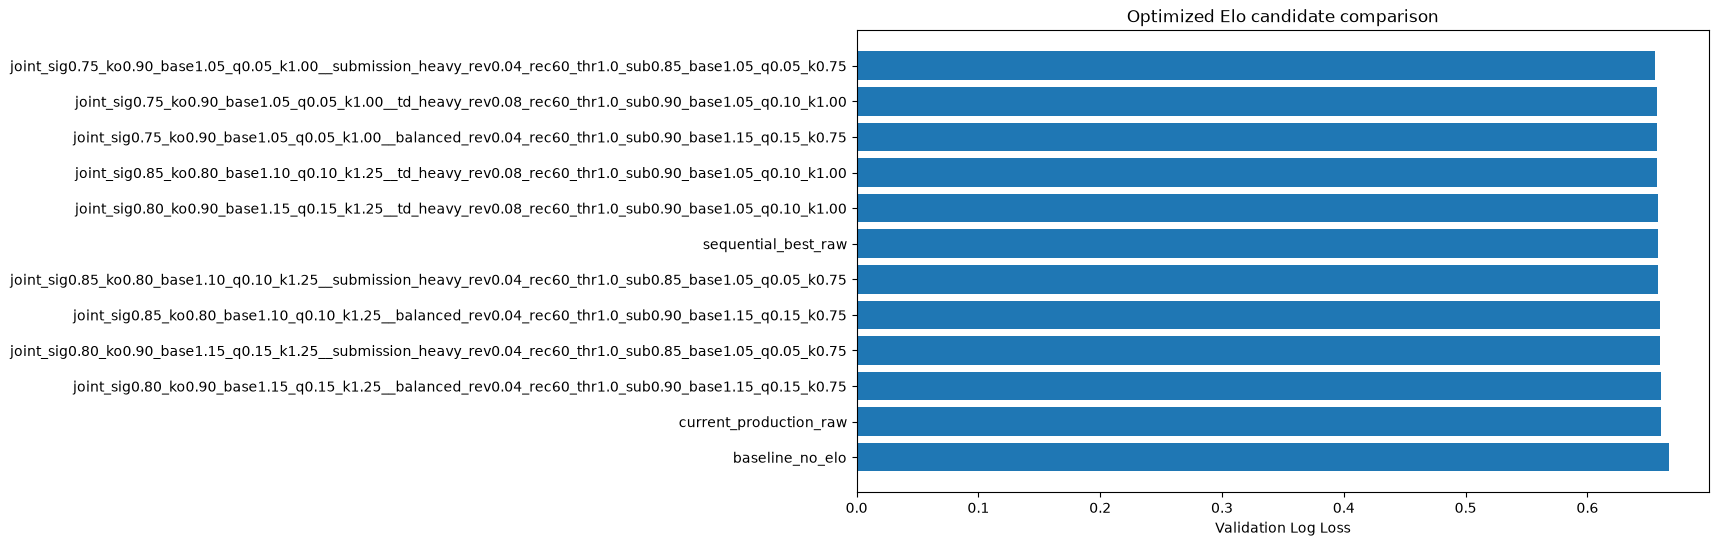

In [76]:
plt.figure(figsize=(11, 6))

plot_df = comparison_df.sort_values(
    "log_loss",
    ascending=True,
)

plt.barh(
    plot_df["candidate"],
    plot_df["log_loss"],
)

plt.gca().invert_yaxis()
plt.xlabel("Validation Log Loss")
plt.title("Optimized Elo candidate comparison")
plt.show()


# Temporal robustness and final candidate selection

A single validation window can reward a configuration that happens to fit one UFC era.

I therefore test the strongest joint candidates on several chronological windows that remain entirely inside the development period.

The untouched final test period is still excluded.

### Final selection rule

I first prefer candidates that improve at least **two of the three** chronological validation windows.

Among those candidates, I select the one with the best **mean Log Loss delta versus the fold-specific baseline**.

The primary validation Log Loss is used only as a secondary tie-breaker.

In [77]:
development_end = validation_end

rolling_folds = [
    {
        "name": "fold_1",
        "train_end": int(n * 0.55),
        "validation_start": int(n * 0.55),
        "validation_end": int(n * 0.65),
    },
    {
        "name": "fold_2",
        "train_end": int(n * 0.65),
        "validation_start": int(n * 0.65),
        "validation_end": int(n * 0.75),
    },
    {
        "name": "fold_3_primary",
        "train_end": train_end,
        "validation_start": train_end,
        "validation_end": validation_end,
    },
]

# I evaluate several of the strongest primary-validation candidates,
# rather than only the single winner.
top_joint_names = (
    joint_df
    .head(min(N_ROBUSTNESS_CANDIDATES, len(joint_df)))["candidate"]
    .tolist()
)

# I always include the sequential best and current production references when available.
for reference_name in [
    "sequential_best_raw",
    "current_production_raw",
]:
    if (
        reference_name in joint_df["candidate"].values
        and reference_name not in top_joint_names
    ):
        top_joint_names.append(reference_name)

robustness_results = []

for fold in rolling_folds:
    fold_train_idx = np.arange(
        0,
        fold["train_end"],
    )

    fold_validation_idx = np.arange(
        fold["validation_start"],
        fold["validation_end"],
    )

    # Baseline for this exact temporal window.
    fold_baseline = fit_and_score(
        None,
        [],
        train_indices=fold_train_idx,
        validation_indices=fold_validation_idx,
    )

    robustness_results.append({
        "fold": fold["name"],
        "candidate": "baseline_no_elo",
        **fold_baseline,
    })

    for candidate_name in top_joint_names:
        features = joint_feature_cache[
            candidate_name
        ]

        metrics = fit_and_score(
            features,
            ALL_RAW_ELO_COLUMNS,
            train_indices=fold_train_idx,
            validation_indices=fold_validation_idx,
        )

        robustness_results.append({
            "fold": fold["name"],
            "candidate": candidate_name,
            **metrics,
        })

robustness_df = pd.DataFrame(
    robustness_results
)

display(
    robustness_df[
        [
            "fold",
            "candidate",
            "log_loss",
            "brier",
            "roc_auc",
            "accuracy",
        ]
    ]
)

,fold,candidate,log_loss,brier,roc_auc,accuracy
0,fold_1,baseline_no_elo,0.665214,0.236418,0.635515,0.603666
1,fold_1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,0.659483,0.233879,0.642715,0.595647
2,fold_1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__td_...,0.662026,0.235060,0.636954,0.585338
3,fold_1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,0.663218,0.235597,0.635604,0.594502
4,fold_1,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__td_...,0.660887,0.234330,0.642978,0.608247
5,fold_1,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__td_...,0.662928,0.235406,0.636812,0.596793
6,fold_1,sequential_best_raw,0.665234,0.236649,0.629286,0.581901
7,fold_1,current_production_raw,0.664416,0.236104,0.633419,0.602520
8,fold_2,baseline_no_elo,0.660760,0.234352,0.643069,0.607102
9,fold_2,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,0.659728,0.233797,0.646361,0.611684


In [78]:
robustness_delta_rows = []

for fold_name, fold_data in robustness_df.groupby("fold"):
    baseline_ll = float(
        fold_data.loc[
            fold_data["candidate"] == "baseline_no_elo",
            "log_loss",
        ].iloc[0]
    )

    for row in fold_data.itertuples(index=False):
        robustness_delta_rows.append({
            "fold": fold_name,
            "candidate": row.candidate,
            "log_loss": row.log_loss,
            "delta_vs_fold_baseline": (
                row.log_loss - baseline_ll
            ),
        })

robustness_delta_df = pd.DataFrame(
    robustness_delta_rows
)

display(
    robustness_delta_df.sort_values(
        ["candidate", "fold"]
    )
)

robustness_summary = (
    robustness_delta_df[
        robustness_delta_df["candidate"]
        != "baseline_no_elo"
    ]
    .groupby("candidate")
    .agg(
        mean_delta_log_loss=(
            "delta_vs_fold_baseline",
            "mean",
        ),
        worst_delta_log_loss=(
            "delta_vs_fold_baseline",
            "max",
        ),
        best_delta_log_loss=(
            "delta_vs_fold_baseline",
            "min",
        ),
        folds_improved=(
            "delta_vs_fold_baseline",
            lambda x: int((x < 0).sum()),
        ),
    )
    .reset_index()
)

# Add primary-validation performance as a secondary criterion.
robustness_summary = robustness_summary.merge(
    joint_df[
        ["candidate", "log_loss"]
    ].rename(
        columns={
            "log_loss": "primary_validation_log_loss"
        }
    ),
    on="candidate",
    how="left",
)

eligible = robustness_summary[
    robustness_summary["folds_improved"] >= 2
].copy()

if eligible.empty:
    print(
        "WARNING: no candidate improved at least two temporal folds. "
        "Falling back to the best mean temporal delta."
    )
    selection_pool = robustness_summary.copy()
else:
    selection_pool = eligible.copy()

selection_pool = selection_pool.sort_values(
    [
        "mean_delta_log_loss",
        "primary_validation_log_loss",
    ],
    ascending=[True, True],
).reset_index(drop=True)

FINAL_CANDIDATE_NAME = selection_pool.iloc[0]["candidate"]

FINAL_CANDIDATE = next(
    item
    for item in joint_configs
    if item["name"] == FINAL_CANDIDATE_NAME
)

BEST_ELO_CONFIG = FINAL_CANDIDATE["config"].copy()
BEST_FEATURE_MODE = "raw"

# Enforce the final design decisions in the saved production configuration.
BEST_ELO_CONFIG["use_effective_for_expectation"] = False
BEST_ELO_CONFIG["max_shrink_low_confidence"] = 0.0
BEST_ELO_CONFIG["max_shrink_high_confidence"] = 0.0

display(
    robustness_summary.sort_values(
        [
            "folds_improved",
            "mean_delta_log_loss",
        ],
        ascending=[False, True],
    )
)

print("Final selected candidate:", FINAL_CANDIDATE_NAME)
print("Final feature mode:", BEST_FEATURE_MODE)

,fold,candidate,log_loss,delta_vs_fold_baseline
0,fold_1,baseline_no_elo,0.665214,0.000000
8,fold_2,baseline_no_elo,0.660760,0.000000
16,fold_3_primary,baseline_no_elo,0.666573,0.000000
7,fold_1,current_production_raw,0.664416,-0.000798
15,fold_2,current_production_raw,0.660402,-0.000357
23,fold_3_primary,current_production_raw,0.660162,-0.006411
3,fold_1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,0.663218,-0.001996
11,fold_2,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,0.663555,0.002795
19,fold_3_primary,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,0.657109,-0.009464
1,fold_1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,0.659483,-0.005731


,candidate,mean_delta_log_loss,worst_delta_log_loss,best_delta_log_loss,folds_improved,primary_validation_log_loss
2,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,-0.005980,-0.001032,-0.011177,3,0.655396
0,current_production_raw,-0.002522,-0.000357,-0.006411,3,0.660162
6,sequential_best_raw,-0.003864,0.000020,-0.008757,2,0.657816
3,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__td_...,-0.003828,0.001183,-0.009480,2,0.657093
1,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__bal...,-0.002888,0.002795,-0.009464,2,0.657109
5,joint_sig0.85_ko0.80_base1.10_q0.10_k1.25__td_...,-0.002878,0.004844,-0.009151,2,0.657422
4,joint_sig0.80_ko0.90_base1.15_q0.15_k1.25__td_...,-0.002332,0.004049,-0.008758,2,0.657815


Final selected candidate: joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
Final feature mode: raw


# Bootstrap the final robust candidate

I bootstrap the **paired primary-validation predictions** of the baseline and the candidate selected by temporal robustness.

This does not replace the untouched final test.

It answers a narrower question:

> Within the primary validation period, is the probability-quality improvement broadly distributed across fights or driven by a small number of examples?

,candidate,n_bootstrap,mean_delta_log_loss,median_delta_log_loss,ci_2_5,ci_97_5,probability_improvement
0,joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__sub...,3000,-0.0111,-0.011053,-0.016697,-0.005558,1.0


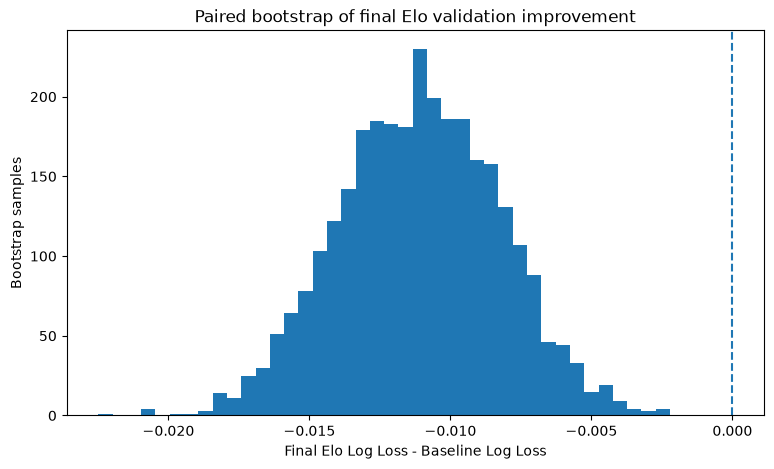

In [79]:
best_validation_probabilities = (
    joint_prediction_cache[FINAL_CANDIDATE_NAME]
)

y_val = (
    df.iloc[validation_idx]["target"]
    .astype(int)
    .to_numpy()
)

baseline_probs = np.asarray(
    baseline_validation_probabilities
)
best_probs = np.asarray(
    best_validation_probabilities
)

bootstrap_deltas = []

for _ in range(N_BOOTSTRAP):
    sample_idx = rng.integers(
        0,
        len(y_val),
        size=len(y_val),
    )

    baseline_ll = log_loss(
        y_val[sample_idx],
        np.clip(
            baseline_probs[sample_idx],
            1e-7,
            1 - 1e-7,
        ),
    )

    best_ll = log_loss(
        y_val[sample_idx],
        np.clip(
            best_probs[sample_idx],
            1e-7,
            1 - 1e-7,
        ),
    )

    bootstrap_deltas.append(
        best_ll - baseline_ll
    )

bootstrap_deltas = np.asarray(
    bootstrap_deltas
)

bootstrap_summary = {
    "candidate": FINAL_CANDIDATE_NAME,
    "n_bootstrap": N_BOOTSTRAP,
    "mean_delta_log_loss": float(
        bootstrap_deltas.mean()
    ),
    "median_delta_log_loss": float(
        np.median(bootstrap_deltas)
    ),
    "ci_2_5": float(
        np.quantile(
            bootstrap_deltas,
            0.025,
        )
    ),
    "ci_97_5": float(
        np.quantile(
            bootstrap_deltas,
            0.975,
        )
    ),
    "probability_improvement": float(
        (bootstrap_deltas < 0).mean()
    ),
}

display(
    pd.DataFrame([bootstrap_summary])
)

plt.figure(figsize=(9, 5))
plt.hist(
    bootstrap_deltas,
    bins=40,
)
plt.axvline(
    0,
    linestyle="--",
)
plt.xlabel(
    "Final Elo Log Loss - Baseline Log Loss"
)
plt.ylabel("Bootstrap samples")
plt.title(
    "Paired bootstrap of final Elo validation improvement"
)
plt.show()

# Save the final optimization results

I save the expanded search tables, temporal-robustness results, bootstrap summary and final production configuration.

`best_elo_config.json` contains the configuration selected by the temporal-robustness rule.

The saved configuration explicitly disables Elo decay and uses Raw Elo expectations.

In [80]:
general_intrinsic_df.to_csv(
    RESULTS_DIR / "01_general_intrinsic_search.csv",
    index=False,
)

general_model_df.to_csv(
    RESULTS_DIR / "02_general_catboost_confirmation.csv",
    index=False,
)

striking_df.to_csv(
    RESULTS_DIR / "03_striking_search.csv",
    index=False,
)

grappling_df.to_csv(
    RESULTS_DIR / "04_grappling_search.csv",
    index=False,
)

confidence_df.to_csv(
    RESULTS_DIR / "05_confidence_search.csv",
    index=False,
)

joint_df.to_csv(
    RESULTS_DIR / "06_joint_raw_search.csv",
    index=False,
)

comparison_df.to_csv(
    RESULTS_DIR / "07_primary_validation_comparison.csv",
    index=False,
)

robustness_df.to_csv(
    RESULTS_DIR / "08_temporal_robustness.csv",
    index=False,
)

robustness_summary.to_csv(
    RESULTS_DIR / "09_temporal_robustness_summary.csv",
    index=False,
)

pd.DataFrame([bootstrap_summary]).to_csv(
    RESULTS_DIR / "10_bootstrap_summary.csv",
    index=False,
)

final_selection = pd.DataFrame([{
    "candidate": FINAL_CANDIDATE_NAME,
    "feature_mode": BEST_FEATURE_MODE,
    "primary_validation_log_loss": float(
        joint_df.loc[
            joint_df["candidate"] == FINAL_CANDIDATE_NAME,
            "log_loss",
        ].iloc[0]
    ),
    "mean_temporal_delta_log_loss": float(
        robustness_summary.loc[
            robustness_summary["candidate"] == FINAL_CANDIDATE_NAME,
            "mean_delta_log_loss",
        ].iloc[0]
    ),
    "folds_improved": int(
        robustness_summary.loc[
            robustness_summary["candidate"] == FINAL_CANDIDATE_NAME,
            "folds_improved",
        ].iloc[0]
    ),
}])

final_selection.to_csv(
    RESULTS_DIR / "11_final_candidate.csv",
    index=False,
)

best_config_path = (
    RESULTS_DIR / "best_elo_config.json"
)

with best_config_path.open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        BEST_ELO_CONFIG,
        f,
        indent=2,
        ensure_ascii=False,
    )

print("Final candidate:", FINAL_CANDIDATE_NAME)
print("Best config saved to:")
print(best_config_path)

Final candidate: joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
Best config saved to:
c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\elo_optimization_final\best_elo_config.json


## Final selected Elo parameters

This is the configuration selected after the expanded search and temporal-robustness filter.

Before changing `build_elo_snapshots.py`, I check that:

- `use_effective_for_expectation` is `False`;
- both shrink parameters are `0.0`;
- the final feature mode is `raw`.

In [81]:
print("Final candidate:", FINAL_CANDIDATE_NAME)
print("Feature mode:", BEST_FEATURE_MODE)
print()

print(json.dumps(
    BEST_ELO_CONFIG,
    indent=2,
    ensure_ascii=False,
))

assert BEST_FEATURE_MODE == "raw"
assert BEST_ELO_CONFIG["use_effective_for_expectation"] is False
assert BEST_ELO_CONFIG["max_shrink_low_confidence"] == 0.0
assert BEST_ELO_CONFIG["max_shrink_high_confidence"] == 0.0

print()
print("Final Raw-Elo consistency checks passed.")

Final candidate: joint_sig0.75_ko0.90_base1.05_q0.05_k1.00__submission_heavy_rev0.04_rec60_thr1.0_sub0.85_base1.05_q0.05_k0.75
Feature mode: raw

{
  "base_elo": 1500.0,
  "elo_scale": 300.0,
  "k_schedule": [
    [
      3,
      30.0
    ],
    [
      6,
      28.0
    ],
    [
      10,
      24.0
    ],
    [
      1000000000,
      20.0
    ]
  ],
  "striking_k_multiplier": 1.0,
  "grappling_k_multiplier": 0.75,
  "confidence_prior_fights": 3.0,
  "inactivity_grace_days": 304,
  "inactivity_tau_days": 730.0,
  "max_shrink_low_confidence": 0.0,
  "max_shrink_high_confidence": 0.0,
  "use_effective_for_expectation": false,
  "striking_sig_share_weight": 0.75,
  "striking_kd_share_weight": 0.25,
  "ko_min_winner_score": 0.9,
  "ko_base_multiplier": 1.05,
  "ko_max_quality_bonus": 0.05,
  "grapple_td_weight": 0.3,
  "grapple_control_weight": 0.25,
  "grapple_sub_weight": 0.3,
  "grapple_recovery_weight": 0.15,
  "grapple_reversal_penalty": 0.04,
  "recovery_scale_seconds": 60.0,
  "s

# Optional untouched final test — run once

I should enable this only after:

- the expanded Elo search has finished;
- the temporal-robustness selection has completed;
- I have accepted the final Raw Elo configuration;
- I will no longer change Elo formulas based on development results.

When enabled, the final model is trained on **train + validation** and evaluated once on the untouched final 15%.

After opening this test set, I should report the result rather than continuing to tune against it.

In [82]:
if RUN_FINAL_TEST:
    best_features = build_candidate_features(
        BEST_ELO_CONFIG
    )

    all_features = pd.concat(
        [
            df[baseline_features].copy(),
            best_features[ALL_RAW_ELO_COLUMNS].copy(),
        ],
        axis=1,
    )

    cat_cols = [
        col
        for col in categorical_features
        if col in all_features.columns
    ]

    development_idx = np.arange(
        0,
        validation_end,
    )

    X_development = prepare_catboost_frame(
        all_features.iloc[development_idx],
        cat_cols,
    )

    X_test = prepare_catboost_frame(
        all_features.iloc[test_idx],
        cat_cols,
    )

    y_development = (
        df.iloc[development_idx]["target"]
        .astype(int)
    )

    y_test = (
        df.iloc[test_idx]["target"]
        .astype(int)
    )

    # I reuse the boosting length selected for this candidate on development validation.
    selected_best_iteration = int(
        joint_df.loc[
            joint_df["candidate"] == FINAL_CANDIDATE_NAME,
            "best_iteration",
        ].iloc[0]
    )

    final_params = FINAL_MODEL_PARAMS.copy()
    final_params["iterations"] = max(
        selected_best_iteration + 1,
        1,
    )

    final_model = CatBoostClassifier(
        **final_params
    )

    final_model.fit(
        X_development,
        y_development,
        cat_features=cat_cols,
        verbose=False,
    )

    test_probabilities = final_model.predict_proba(
        X_test
    )[:, 1]

    test_metrics = evaluate_probabilities(
        y_test,
        test_probabilities,
    )

    final_test_df = pd.DataFrame([{
        "candidate": FINAL_CANDIDATE_NAME,
        "feature_mode": "raw",
        "iterations": final_params["iterations"],
        **test_metrics,
    }])

    display(final_test_df)

    final_test_df.to_csv(
        RESULTS_DIR / "FINAL_TEST_RESULT.csv",
        index=False,
    )
else:
    print(
        "Final test is still closed. "
        "Set RUN_FINAL_TEST=True only when the Elo design is frozen."
    )

Final test is still closed. Set RUN_FINAL_TEST=True only when the Elo design is frozen.


# Final Conclusions

This notebook completed the final development-stage optimization of the Elo system before opening the untouched test set.

The main objective was not simply to find the configuration with the lowest Log Loss on one validation period. I wanted to find an Elo formulation that:

* improves the baseline model;
* improves the previous production Elo;
* remains useful across different chronological periods;
* produces better probability estimates rather than only better hard classifications;
* avoids unnecessary complexity such as duplicated Raw/Effective ratings;
* and can be frozen before evaluating the final test set.

The final results support keeping Elo as an important part of the UFC fight prediction pipeline.

---

## 1. Overall model improvement

The main validation results were:

| Model                   |     Log Loss |  Brier Score |      ROC AUC |     Accuracy |
| ----------------------- | -----------: | -----------: | -----------: | -----------: |
| Baseline without Elo    |     0.666573 |     0.237088 |     0.627765 |     0.599237 |
| Previous production Elo |     0.660162 |     0.234020 |     0.644868 |     0.606870 |
| **Final optimized Elo** | **0.655396** | **0.231831** | **0.653316** | **0.610687** |

The optimized Elo system therefore improved every reported metric.

Compared with the baseline:

* Log Loss decreased by approximately **0.01118**, or about **1.68%**.
* Brier Score also decreased, meaning the probability estimates became more accurate.
* ROC AUC increased from approximately **0.628 to 0.653**.
* Accuracy increased by approximately **1.1 percentage points**.

The important point is that the optimized Elo also improved on the previous production Elo.

This means that Elo itself was already useful, but its exact formulation still contained meaningful room for improvement.

---

## 2. General Elo

The expanded General Elo search strongly supported an Elo scale of:

```text
ELO_SCALE = 300
```

Configurations using a scale of 300 consistently outperformed the equivalent configurations using 400 or 500.

The final General K schedule remains conservative:

```text
0–2 previous UFC fights   → K = 30
3–5 previous UFC fights   → K = 28
6–9 previous UFC fights   → K = 24
10+ previous UFC fights   → K = 20
```

This is very close to the original schedule.

The main difference is that the initial K was reduced slightly from 32 to 30.

I interpret this as evidence that early UFC fights should still change the rating quickly, but not quite as aggressively as in the first implementation.

The isolated General Elo experiment slightly preferred effective ratings for calculating expectations. However, the complete optimization process showed that inactivity-adjusted ratings were not robust enough to justify maintaining a separate Effective Elo system.

The final production decision is therefore:

```text
Expected score → Raw Elo
Elo decay      → Disabled
```

---

## 3. Striking Elo

The Striking optimization produced an important methodological result.

The best Striking configuration **when evaluated independently** was not the same configuration that appeared in the final joint model.

The isolated Striking optimum preferred approximately:

```text
Significant strikes weight = 0.85
Knockdown weight           = 0.15
KO minimum score           = 0.80
KO base multiplier         = 1.10
KO quality bonus           = 0.10
Striking K multiplier      = 1.25
```

However, when Striking was combined with the best General and Grappling configurations, the temporally robust final system preferred:

```text
Significant strikes weight = 0.75
Knockdown weight           = 0.25
KO minimum score           = 0.90
KO base multiplier         = 1.05
KO quality bonus           = 0.05
Striking K multiplier      = 1.00
```

This is a useful result because it shows why the joint search was necessary.

The independently optimal feature formulation is not necessarily the globally optimal formulation once all Elo dimensions interact inside CatBoost.

The final Striking Elo gives more importance to knockdowns than the original system:

```text
15% → 25%
```

It also treats a KO/TKO as strong evidence by enforcing a minimum performance score of:

```text
0.90
```

At the same time, the additional KO multipliers are smaller.

This avoids rewarding the same information too aggressively through several mechanisms simultaneously.

The final interpretation is that knockdowns and KO/TKO outcomes contain useful information, but most of the adjustment should come from the performance score and the Elo expectation itself rather than from very large additional multipliers.

---

## 4. Grappling Elo

The expanded Grappling search selected a **submission-heavy** configuration.

The final weights are:

```text
Takedowns          = 0.30
Control            = 0.25
Submission threat  = 0.30
Recovery           = 0.15
```

This differs from the initial implementation:

```text
Takedowns          = 0.35
Control            = 0.30
Submission threat  = 0.20
Recovery           = 0.15
```

The largest change is therefore the increased importance of submission attempts.

Takedowns remain important, but the results do not support a purely takedown-heavy representation of grappling skill.

Instead, takedowns and submission threat receive equal weight.

The final auxiliary Grappling parameters are:

```text
Reversal penalty           = 0.04
Recovery scale             = 60 seconds
Submission threat scale    = 1.0

Submission minimum score   = 0.85
Submission base multiplier = 1.05
Submission quality bonus   = 0.05
```

The Grappling K multiplier is:

```text
0.75
```

This is one of the more stable findings from the experiments.

Grappling ratings appear to benefit from updating more slowly than General Elo.

A single fight can strongly depend on stylistic matchup, so using a lower K makes the Grappling ratings less sensitive to one unusual performance.

---

## 5. Confidence

The expanded search selected:

```text
confidence_prior_fights = 3
```

Therefore the final confidence function is:

$$
C(n)=\frac{n}{n+3}
$$

instead of the previous:

$$
C(n)=\frac{n}{n+5}
$$

This means confidence in the Elo ratings now increases somewhat faster.

For example:

| Previous UFC fights | Prior = 5 | Prior = 3 |
| ------------------: | --------: | --------: |
|                   1 |      0.17 |      0.25 |
|                   3 |      0.38 |      0.50 |
|                   5 |      0.50 |      0.63 |
|                  10 |      0.67 |      0.77 |

This does not mean that a fighter's skill is fully known after only a few UFC fights.

It only tells CatBoost that an Elo rating based on several UFC observations should be trusted more than the default rating of a debutant.

---

## 6. Inactivity and Effective Elo

The final system does **not** use Effective Elo.

Previous experiments showed that manually shrinking Elo toward 1500 after inactivity did not consistently improve the model.

The final configuration therefore explicitly sets:

```text
use_effective_for_expectation = False

max_shrink_low_confidence  = 0.0
max_shrink_high_confidence = 0.0
```

This means:

$$
Elo_{\text{effective}} = Elo_{\text{raw}}
$$

and there is no reason to include both as model features.

The final feature set therefore uses only Raw Elo.

However, inactivity itself is still retained as information.

The model receives features such as:

```text
elo_days_inactive_before
days_since_last_fight
```

This gives CatBoost the possibility of learning whether inactivity matters without manually assuming how much a fighter's skill should decay.

I consider this cleaner than modifying the rating itself.

---

# 7. Final Elo configuration

The final selected development configuration is:

```text
GENERAL ELO
────────────────────────────────
Base Elo                      1500
Elo scale                      300

K:
0–2 previous fights             30
3–5                             28
6–9                             24
10+                             20

Expected-score rating          Raw Elo


STRIKING ELO
────────────────────────────────
Significant strikes            0.75
Knockdowns                     0.25

KO minimum score               0.90
KO base multiplier             1.05
KO quality bonus               0.05

Striking K multiplier          1.00


GRAPPLING ELO
────────────────────────────────
Takedowns                      0.30
Control                        0.25
Submission threat              0.30
Recovery                       0.15

Reversal penalty               0.04
Recovery scale                 60 s
Submission threat scale        1.0

Submission minimum score       0.85
Submission base multiplier     1.05
Submission quality bonus       0.05

Grappling K multiplier         0.75


CONFIDENCE
────────────────────────────────
Confidence prior fights           3


INACTIVITY
────────────────────────────────
Elo decay                        No
Effective Elo                    No
Inactivity as model feature     Yes
```

---

# 8. Temporal robustness

The final candidate was not selected only because it had the best primary-validation Log Loss.

It was also tested on three chronological validation periods.

The results were:

| Fold   | Baseline Log Loss | Final Elo Log Loss |         Delta |
| ------ | ----------------: | -----------------: | ------------: |
| Fold 1 |          0.665214 |           0.659483 | **-0.005731** |
| Fold 2 |          0.660760 |           0.659728 | **-0.001032** |
| Fold 3 |          0.666573 |           0.655396 | **-0.011177** |

The optimized Elo system therefore improved:

```text
3 / 3 chronological validation windows
```

Its mean Log Loss improvement across the folds was:

```text
Mean delta = -0.005980
```

Most importantly, even the worst temporal result remained an improvement:

```text
Worst delta = -0.001032
```

This is stronger evidence than simply obtaining the best result on the primary validation set.

It suggests that the useful Elo signal is not limited to one particular UFC period.

---

# 9. Bootstrap analysis

I also performed a paired bootstrap comparison between the final Elo model and the baseline on the primary validation period.

Using:

```text
3,000 bootstrap samples
```

the results were:

```text
Mean Log Loss delta   = -0.011100
Median Log Loss delta = -0.011053

95% bootstrap interval:
[-0.016697, -0.005558]

Probability of improvement = 1.000
```

Every bootstrap sample produced a lower Log Loss for the optimized Elo model.

The entire 95% bootstrap interval is also below zero.

This does not replace the untouched final test set, but it provides strong evidence that the improvement inside the primary validation period is broadly distributed across the fights rather than being caused by a very small number of examples.

---

# 10. Final Interpretation Checklist

## 1. Did the expanded search still favour an Elo scale close to the previously discovered region?

**Yes.**

The expanded search strongly favoured:

```text
ELO_SCALE = 300
```

Configurations with scales of 400 and 500 consistently produced worse intrinsic Elo results.

This confirms the main result of the first optimization pass.

---

## 2. Did the conservative General K schedule remain competitive?

**Yes.**

The final schedule remains very conservative and is only slightly different from the initial one.

The selected schedule is:

```text
30 / 28 / 24 / 20
```

instead of:

```text
32 / 28 / 24 / 20
```

The only meaningful change is a slightly smaller K for the first three UFC fights.

Therefore the original assumption that experienced fighters should have increasingly stable Elo ratings remains supported.

---

## 3. Did Striking still favour a faster K multiplier than General Elo?

**Not in the final joint configuration.**

The isolated Striking search did favour:

```text
K multiplier = 1.25
```

However, the final temporally robust joint candidate selected:

```text
K multiplier = 1.00
```

Therefore I should not conclude that Striking must update faster than General Elo.

The expanded search instead suggests that a faster Striking K can work well in isolation, but the normal General K schedule interacts better with the final Grappling and Striking formulation.

---

## 4. Did Grappling still favour a slower K multiplier than General Elo?

**Yes.**

The final Grappling multiplier is:

```text
0.75
```

This result remained stable after the expanded search.

I therefore keep Grappling ratings less reactive to individual fights than General Elo.

---

## 5. Did the Striking search continue to give meaningful weight to knockdowns and KO/TKO information?

**Yes.**

The final system gives:

```text
25% weight to knockdown share
```

compared with 15% in the original implementation.

KO/TKO winners also receive a minimum performance score of:

```text
0.90
```

However, the additional KO multipliers are moderate.

This suggests that knockdowns and KO/TKO outcomes are informative, but their contribution should not be amplified excessively through multiple simultaneous bonuses.

---

## 6. Did the Grappling search continue to favour takedowns without making control, submissions or recovery irrelevant?

**Partially.**

Takedowns remain important, but the final expanded search did **not** choose a takedown-heavy configuration.

The final weights are:

```text
Takedowns          = 0.30
Control            = 0.25
Submission threat  = 0.30
Recovery           = 0.15
```

Submission threat is therefore as important as takedowns.

The result supports a multi-dimensional representation of grappling rather than using takedowns or control time as dominant proxies for grappling skill.

---

## 7. Did the confidence prior remain stable?

**No.**

The first optimization pass preferred:

```text
prior = 5
```

while the expanded search preferred:

```text
prior = 3
```

The final system therefore allows confidence to increase somewhat faster with UFC experience.

This parameter should be considered part of the optimized configuration rather than a result that remained unchanged from the initial design.

---

## 8. Does the selected Raw Elo candidate improve at least two chronological validation windows?

**Yes.**

It improves all three:

```text
Fold 1 → improved
Fold 2 → improved
Fold 3 → improved
```

Therefore:

```text
folds_improved = 3 / 3
```

---

## 9. Is its mean temporal Log Loss delta better than the baseline?

**Yes.**

The mean delta is:

```text
-0.005980
```

A negative value means lower Log Loss than the baseline.

Even the worst of the three folds still improved by approximately:

```text
-0.001032
```

---

## 10. Does the paired bootstrap support the improv
